# YOLOv8m fine-tune — bản đồ + lộ trình có hướng (42 lớp)

Notebook mở rộng đúng 38 lớp bản đồ cũ thành 42 lớp: giữ nguyên ID 0–37 và thêm `route_up`, `route_down`, `route_left`, `route_right` ở ID 38–41. Mỗi cạnh đầu ra giữ riêng `status` mặt đường và `route_status`; route không ghi đè normal/crowded/covered/closed.

Luồng chạy chỉ dùng ảnh của 5 chuyến demo mỗi episode: nếu đầu vào là ZIP, notebook chỉ đọc metadata `scenes.json` và giải nén ảnh có route demo, không bung ảnh query. Từ ảnh demo, notebook sinh nhãn map + route, fine-tune YOLOv8m, rồi kiểm tra khả năng ráp lại route.

Mười chiến thuật cũ vẫn được dùng ở bước nhận diện robot: R0 Tia Chớp, R1 Yên Tĩnh, R2 Mái Hiên, R3 Mây Mưa, R4 Sơn Dương, R5 Thẳng Tắp, R6 Hỏa Tốc, R7 Nâng Niu, R8 Lề Phải, R9 Tham Lam. YOLO không tự gán ID robot; nó xuất route demo có hướng để bước suy luận phía sau so với 10 policy này.

Đầu vào: thư mục hoặc ZIP `delivery_public` có train/validation, `scenes.json`, ảnh demo; checkpoint map cũ 38 lớp, ví dụ `best.pt`. Các JSON rời không có ảnh nên chưa đủ để train.

Nhãn bbox route được ước lượng từ chuỗi node + offset sang bên phải, có thể tinh chỉnh theo màu mẫu route trong legend. Hãy xem QC theo đủ 4 style trước khi train. Bộ giải mã giữ trạng thái đường và route riêng, rồi ráp `route_moves` từ vị trí robot qua via tới goal.


In [ ]:
# CELL 1 — Đọc final.zip từ Google Drive và cấu hình
from pathlib import Path
import os
import json
import zipfile
import random
import shutil
import math
import hashlib

# Google Drive cần được mount khi chạy trên Google Colab.
# Sửa đường dẫn này nếu final.zip nằm trong thư mục khác.
DRIVE_ZIP_PATH = Path("/content/drive/MyDrive/FINAL1_data.zip")

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    # Ngoài Colab, hãy đặt DRIVE_ZIP_PATH thành đường dẫn ZIP đã tải về máy.
    pass

if not DRIVE_ZIP_PATH.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy file ZIP: {DRIVE_ZIP_PATH}\n"
        "Hãy kiểm tra vị trí final.zip trên Google Drive hoặc sửa DRIVE_ZIP_PATH."
    )

OUTPUT_DIR = Path("./yolo_map_route_42class")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OLD_MODEL_PATH = Path("/content/best (5).pt")  # checkpoint YOLO map cũ, đúng 38 class

BOX_PAD = 10
IMGSZ = 1024
EPOCHS = 80
PATIENCE = 18
BATCH_SIZE = 6
WORKERS = 2
SEED = 20261015

# Ước lượng hình học nét route: offset bên phải vector chuyển động
# (tọa độ ảnh y tăng xuống).
ROUTE_LANE_OFFSET_RATIO = 0.10
ROUTE_CENTER_T = 0.50
ROUTE_BOX_LENGTH_RATIO = 0.76
ROUTE_BOX_WIDTH_RATIO = 0.16
ROUTE_COLOR_MAX_DIST = 42.0
ROUTE_COLOR_MIN_PIXELS = 5
ROUTE_USE_LEGEND_COLOR = True

# Không lật, đảo hoặc xoay ảnh vì sẽ làm đổi hướng tuyệt đối và one-way.
TRAIN_PHOTO_VARIANTS = True

# Đọc metadata trực tiếp trong ZIP. Các cell sau có thể dùng member và prefix
# để chỉ lấy ảnh của những scene có scene.route.moves.
ZIP_MODE = True
ZIP_SCENE_MEMBERS = {}
ZIP_SPLIT_PREFIX = {}

DATA_ARCHIVE = DRIVE_ZIP_PATH
DATA_ROOT = OUTPUT_DIR / "source_metadata"
IMAGE_ROOT = OUTPUT_DIR / "source_demo_images"

def _normalise_zip_name(name):
    return name.replace("\\", "/").lstrip("./")

def _find_scene_member(names, split):
    """Tìm split/scenes.json, kể cả khi ZIP có thư mục gốc bọc bên ngoài."""
    suffix = f"{split}/scenes.json"
    matches = [
        _normalise_zip_name(name)
        for name in names
        if _normalise_zip_name(name).endswith(suffix)
    ]
    if not matches:
        raise FileNotFoundError(
            f"Không tìm thấy {suffix} bên trong {DATA_ARCHIVE.name}."
        )

    # Ưu tiên đường dẫn có delivery_public làm thư mục gốc.
    preferred = [
        name for name in matches
        if f"delivery_public/{suffix}" in name
    ]
    return min(preferred or matches, key=len)

with zipfile.ZipFile(DATA_ARCHIVE, "r") as zf:
    zip_names = zf.namelist()

    for split in ("train", "validation"):
        member = _find_scene_member(zip_names, split)
        ZIP_SCENE_MEMBERS[split] = member

        suffix = f"{split}/scenes.json"
        ZIP_SPLIT_PREFIX[split] = member[:-len(suffix)]

        # Chỉ giải nén scenes.json; không bung toàn bộ ảnh trong ZIP.
        dest = DATA_ROOT / split / "scenes.json"
        dest.parent.mkdir(parents=True, exist_ok=True)
        dest.write_bytes(zf.read(member))

TRAIN_DIR = IMAGE_ROOT / "train"
VAL_DIR = IMAGE_ROOT / "validation"
TRAIN_SCENES_PATH = DATA_ROOT / "train" / "scenes.json"
VAL_SCENES_PATH = DATA_ROOT / "validation" / "scenes.json"

if not TRAIN_SCENES_PATH.is_file() or not VAL_SCENES_PATH.is_file():
    raise RuntimeError("Không đọc được scenes.json của train hoặc validation.")

print("Google Drive ZIP:", DATA_ARCHIVE.resolve())
print("Cấu trúc dữ liệu: delivery_public/{train,validation,test}/...")
print("Train scenes:", ZIP_SCENE_MEMBERS["train"])
print("Validation scenes:", ZIP_SCENE_MEMBERS["validation"])
print("Train metadata:", TRAIN_SCENES_PATH.resolve())
print("Validation metadata:", VAL_SCENES_PATH.resolve())
print("ZIP_MODE:", ZIP_MODE, "| chưa bung toàn bộ ảnh")
print("YOLO 38-class checkpoint:", OLD_MODEL_PATH.resolve())
print("Output:", OUTPUT_DIR.resolve())

Google Drive ZIP: /content/drive/MyDrive/FINAL1_data.zip
Cấu trúc dữ liệu: delivery_public/{train,validation,test}/...
Train scenes: delivery_public/train/scenes.json
Validation scenes: delivery_public/validation/scenes.json
Train metadata: /content/yolo_map_route_42class/source_metadata/train/scenes.json
Validation metadata: /content/yolo_map_route_42class/source_metadata/validation/scenes.json
ZIP_MODE: True | chưa bung toàn bộ ảnh
YOLO 38-class checkpoint: /content/best (5).pt
Output: /content/yolo_map_route_42class


In [ ]:
# CELL 2 — Dependencies (Colab/Jupyter)
%pip install -q ultralytics opencv-python-headless pyyaml matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 83.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 12.1 MB/s eta 0:00:00


In [ ]:
import cv2, numpy as np, yaml, matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display
from matplotlib.patches import Rectangle

CLASSES = [
    'canteen', 'clinic', 'dorm', 'gate', 'lab', 'lecture', 'library', 'office', 'parking', 'sports',
    'robot_up', 'robot_down', 'robot_left', 'robot_right',
    'edge_type_1', 'edge_type_2', 'edge_type_3',
    'print_edge_1', 'print_edge_2', 'print_edge_3',
    'closed', 'stairs', 'oneway_up', 'oneway_down', 'oneway_left', 'oneway_right',
    'weather_sun', 'weather_cloud', 'weather_rain',
    'swatch_edge_1', 'swatch_edge_2', 'swatch_edge_3',
    'swatch_print_1', 'swatch_print_2', 'swatch_print_3',
    'txt_normal', 'txt_crowded', 'txt_covered',
    'route_up', 'route_down', 'route_left', 'route_right'
]
CLASS_MAP     = {n: i for i, n in enumerate(CLASSES)}
VISUAL_TO_IDX = {'normal': 1, 'crowded': 2, 'covered': 3}


def to_yolo(xmin, ymin, xmax, ymax, w, h):
    xc, yc = ((xmin + xmax) / 2) / w, ((ymin + ymax) / 2) / h
    bw, bh = (xmax - xmin) / w, (ymax - ymin) / h
    c = lambda v: max(0.0, min(1.0, v))
    return c(xc), c(yc), c(bw), c(bh)


def oneway_class(edge, rc1, rc2):
    r_dst, c_dst = edge['oneway_to']
    r_src, c_src = rc1 if tuple(edge['oneway_to']) == rc2 else rc2
    if c_dst > c_src: return 'oneway_right'
    if c_dst < c_src: return 'oneway_left'
    if r_dst > r_src: return 'oneway_down'
    if r_dst < r_src: return 'oneway_up'
    return None


def scene_to_lines(scene, w_orig, h_orig):
    """1 scene -> list dòng nhãn YOLO.
    THAY ĐỔI CHÍNH: mỗi cạnh có icon được ghi THÀNH 2 BOX CÙNG TOẠ ĐỘ:
        (1) box kiểu nét  (edge_type_k / print_edge_k)  -> model học status
        (2) box icon      (stairs / oneway_*)            -> model học icon
    Cạnh 'closed' vẫn là 1 box 'closed' (closed không đi kèm stairs/oneway)."""
    is_print  = (scene.get('style') == 'print')
    prefix    = 'print_edge' if is_print else 'edge_type'
    road_look = scene.get('road_look', {})
    lines = []

    def add(cls_name, bbox):
        if cls_name is None or cls_name not in CLASS_MAP: return
        xc, yc, w, h = to_yolo(*bbox, w_orig, h_orig)
        lines.append(f"{CLASS_MAP[cls_name]} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")

    node_xy = {tuple(n['rc']): n['xy'] for n in scene['nodes']}

    # ---- CẠNH
    for e in scene.get('edges', []):
        rc1, rc2 = tuple(e['a']), tuple(e['b'])
        if rc1 not in node_xy or rc2 not in node_xy: continue
        (x1, y1), (x2, y2) = node_xy[rc1], node_xy[rc2]
        box = [min(x1, x2) - BOX_PAD, min(y1, y2) - BOX_PAD,
               max(x1, x2) + BOX_PAD, max(y1, y2) + BOX_PAD]
        status = e.get('status')

        if status == 'closed':
            add('closed', box)
            continue

        # (1) box kiểu nét: LUÔN có, kể cả cạnh có icon. road_look = tráo đổi nét <-> status theo từng scene
        look = VISUAL_TO_IDX.get(road_look.get(status, status))
        if look is not None:
            add(f"{prefix}_{look}", box)

        # (2) box icon cùng toạ độ
        if e.get('oneway_to') is not None:
            add(oneway_class(e, rc1, rc2), box)
        if e.get('stairs'):
            add('stairs', box)

    # ---- ĐỊA ĐIỂM
    for lm in scene.get('landmarks', []):
        rc = tuple(lm['rc'])
        if rc in node_xy:
            x, y = node_xy[rc]
            add(lm['type'], [x - 20, y - 20, x + 20, y + 20])

    # ---- ROBOT
    if 'robot' in scene and tuple(scene['robot']['rc']) in node_xy:
        x, y = node_xy[tuple(scene['robot']['rc'])]
        add(f"robot_{scene['robot']['heading'].lower()}", [x - 20, y - 20, x + 20, y + 20])

    # ---- THỜI TIẾT
    if scene.get('weather_box'):
        add('weather_sun' if scene.get('weather', 'dry') == 'dry' else 'weather_rain', scene['weather_box'])

    # ---- CHÚ GIẢI
    for leg in scene.get('legend', []):
        kind = leg.get('kind')
        if kind in ('normal', 'crowded', 'covered'):
            idx = VISUAL_TO_IDX.get(road_look.get(kind, kind), 1)
            if leg.get('swatch'):
                add(f"swatch_{'print' if is_print else 'edge'}_{idx}", leg['swatch'])
            if leg.get('label'):
                add(f"txt_{kind}", leg['label'])
    return lines


# Route labels appended as class IDs 38..41; old classes 0..37 stay untouched.
MOVE_TO_DIRECTION = {0: 'route_up', 1: 'route_down', 2: 'route_left', 3: 'route_right'}
MOVE_TO_DRC = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
DIRECTION_TO_MOVE = {v:k for k,v in MOVE_TO_DIRECTION.items()}


def _route_reference_lab(image_bgr, scene):
    """Lấy màu nét route từ swatch kind=route; chỉ dùng trong ROI route dự kiến."""
    if image_bgr is None or not ROUTE_USE_LEGEND_COLOR:
        return None
    entry=next((x for x in scene.get('legend',[]) if x.get('kind')=='route' and x.get('swatch')),None)
    if entry is None:
        return None
    x1,y1,x2,y2=[int(round(v)) for v in entry['swatch']]
    crop=image_bgr[max(0,y1):min(image_bgr.shape[0],y2),max(0,x1):min(image_bgr.shape[1],x2)]
    if crop.size==0 or crop.shape[0]<4 or crop.shape[1]<4:
        return None
    lab=cv2.cvtColor(crop,cv2.COLOR_BGR2LAB).astype(np.float32)
    border=np.concatenate([lab[0],lab[-1],lab[:,0],lab[:,-1]],axis=0)
    bg=np.median(border,axis=0)
    dist=np.linalg.norm(lab-bg,axis=2)
    ink=lab[dist>18.0]
    if len(ink)<ROUTE_COLOR_MIN_PIXELS:
        return None
    # Median bền với viền hộp/anti-alias; với swatch có nhiều nét, màu chính chiếm đa số.
    return np.median(ink,axis=0)


def route_boxes(scene, w, h, image_bgr=None):
    """Sinh một box route có hướng cho mỗi bước demo.
    Tọa độ strip nằm bên phải hướng đi; nếu tìm được màu route từ legend, box được siết theo pixel thật.
    """
    route=scene.get('route') or {}
    moves,path=route.get('moves'),route.get('nodes')
    if moves is None or path is None:
        return []
    if len(path)!=len(moves)+1:
        raise ValueError(f"{scene['scene_id']}: route.nodes phải bằng len(route.moves)+1")
    node_xy={tuple(n['rc']):np.asarray(n['xy'],dtype=float) for n in scene.get('nodes',[])}
    ref_lab=_route_reference_lab(image_bgr,scene)
    image_lab=cv2.cvtColor(image_bgr,cv2.COLOR_BGR2LAB).astype(np.float32) if image_bgr is not None and ref_lab is not None else None
    out=[]
    for i,move0 in enumerate(moves):
        move=int(move0); a=tuple(path[i]); b=tuple(path[i+1])
        if move not in MOVE_TO_DRC or (b[0]-a[0],b[1]-a[1])!=MOVE_TO_DRC[move]:
            raise ValueError(f"{scene['scene_id']}: route move/node mismatch at step {i}: {a}->{b}, move={move}")
        if a not in node_xy or b not in node_xy:
            raise KeyError(f"{scene['scene_id']}: missing node coordinate {a} or {b}")
        p0,p1=node_xy[a],node_xy[b]; vec=p1-p0; length=float(np.linalg.norm(vec))
        if length<4: continue
        unit=vec/length
        right=np.array([-unit[1],unit[0]],dtype=float) # y-down image coordinates: this is the visual right side
        center=p0+ROUTE_CENTER_T*vec+ROUTE_LANE_OFFSET_RATIO*length*right
        long_len=ROUTE_BOX_LENGTH_RATIO*length
        short_len=max(6.0,ROUTE_BOX_WIDTH_RATIO*length)
        bw=abs(unit[0])*long_len+abs(right[0])*short_len
        bh=abs(unit[1])*long_len+abs(right[1])*short_len
        geom=[max(0.,center[0]-bw/2),max(0.,center[1]-bh/2),min(float(w),center[0]+bw/2),min(float(h),center[1]+bh/2)]
        box=geom
        if image_lab is not None:
            # Tìm đúng nét trong vùng hẹp quanh lane dự kiến, tránh lấy road box song song bên cạnh.
            gx1,gy1,gx2,gy2=geom
            pad=max(3,int(.04*length))
            x1=max(0,int(gx1)-pad); y1=max(0,int(gy1)-pad)
            x2=min(w,int(gx2)+pad+1); y2=min(h,int(gy2)+pad+1)
            roi=image_lab[y1:y2,x1:x2]
            if roi.size:
                mask=np.linalg.norm(roi-ref_lab.reshape(1,1,3),axis=2)<=ROUTE_COLOR_MAX_DIST
                yy,xx=np.where(mask)
                if len(xx)>=ROUTE_COLOR_MIN_PIXELS:
                    # Nới nhẹ bbox để model học cả nét đứt/mũi tên anti-alias.
                    px=3
                    box=[max(0.,x1+float(xx.min())-px),max(0.,y1+float(yy.min())-px),
                         min(float(w),x1+float(xx.max())+1+px),min(float(h),y1+float(yy.max())+1+px)]
        if box[2]-box[0]>=2 and box[3]-box[1]>=2:
            out.append((MOVE_TO_DIRECTION[move],box))
    return out


def scene_to_all_lines(scene,w,h,image_bgr=None):
    lines=scene_to_lines(scene,w,h)
    for name,box in route_boxes(scene,w,h,image_bgr):
        xc,yc,bw,bh=to_yolo(*box,w,h)
        lines.append(f"{CLASS_MAP[name]} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
    return lines


In [ ]:
# CELL 3 — Đọc metadata, giữ riêng 5 demo và chỉ chuẩn bị ảnh demo
from tqdm.auto import tqdm
for p in (TRAIN_SCENES_PATH,VAL_SCENES_PATH):
    if not p.is_file(): raise FileNotFoundError(f'Thiếu {p}; cần metadata train + validation.')
_ALL_TRAIN_SCENES=json.loads(TRAIN_SCENES_PATH.read_text(encoding='utf-8'))
_ALL_VAL_SCENES=json.loads(VAL_SCENES_PATH.read_text(encoding='utf-8'))

def is_demo(sc):
    return (sc.get('route') or {}).get('moves') is not None

TRAIN_SCENES=[s for s in _ALL_TRAIN_SCENES if is_demo(s)]
VAL_SCENES=[s for s in _ALL_VAL_SCENES if is_demo(s)]
if not TRAIN_SCENES or not VAL_SCENES:
    raise RuntimeError('Không tìm thấy scene demo có route.moves trong train hoặc validation.')

def _archive_image_member(split,scene):
    rel=Path(scene['image']).as_posix().lstrip('./')
    prefix=ZIP_SPLIT_PREFIX[split]
    candidate=prefix+f'{split}/{rel}'
    with zipfile.ZipFile(DATA_ARCHIVE) as zf:
        names=set(zf.namelist())
        if candidate in names: return candidate
        # Một số gói lưu đường dẫn ảnh khác nhau; chỉ tìm đúng ảnh demo hiện tại.
        suffix=f'/{split}/{rel}'
        matches=[n for n in names if n.replace('\\','/').endswith(suffix)]
        if len(matches)==1: return matches[0]
        # Trường hợp scene.image đã bao gồm prefix split.
        matches=[n for n in names if n.replace('\\','/').endswith('/'+rel) or n==rel]
        if len(matches)==1: return matches[0]
    raise FileNotFoundError(f"Không tìm được ảnh demo trong ZIP: {split}/{scene['image']}")

def resolve_image(split_dir,scene):
    rel=Path(scene['image'])
    for p in (split_dir/rel,split_dir/'images'/rel.name,split_dir/rel.name):
        if p.is_file(): return p
    raise FileNotFoundError(f"Thiếu ảnh demo {scene['scene_id']}: {scene['image']}")

def extract_demo_images(split,root,scenes):
    if not ZIP_MODE: return
    target_root=root
    count=0
    with zipfile.ZipFile(DATA_ARCHIVE) as zf:
        for sc in tqdm(scenes,desc=f'extract {split} demos'):
            member=_archive_image_member(split,sc)
            rel=Path(sc['image'])
            # Giữ cấu trúc đường dẫn tương đối mà resolve_image sẽ thử.
            dest=target_root/rel
            if dest.exists(): continue
            dest.parent.mkdir(parents=True,exist_ok=True)
            with zf.open(member) as src, dest.open('wb') as dst:
                shutil.copyfileobj(src,dst)
            count+=1
    print(f'{split}: extracted {count} demo images; query images skipped')

extract_demo_images('train',TRAIN_DIR,TRAIN_SCENES)
extract_demo_images('validation',VAL_DIR,VAL_SCENES)

def check_split(name,root,all_scenes,demo_scenes):
    route_steps=sum(len((s.get('route') or {}).get('moves') or []) for s in demo_scenes)
    for s in demo_scenes: resolve_image(root,s)
    print(f'{name}: {len(demo_scenes)} demo images retained / {len(all_scenes)} total scenes; {route_steps} route steps; images present')

check_split('train',TRAIN_DIR,_ALL_TRAIN_SCENES,TRAIN_SCENES)
check_split('validation',VAL_DIR,_ALL_VAL_SCENES,VAL_SCENES)
assert len(CLASSES)==42 and CLASSES[38:]==['route_up','route_down','route_left','route_right']


extract train demos:   0%|          | 0/1250 [00:00<?, ?it/s]

train: extracted 0 demo images; query images skipped


extract validation demos:   0%|          | 0/250 [00:00<?, ?it/s]

validation: extracted 0 demo images; query images skipped
train: 1250 demo images retained / 2750 total scenes; 11598 route steps; images present
validation: 250 demo images retained / 550 total scenes; 3067 route steps; images present


In [ ]:
# CELL 4 — Xuất labels 42 class; giữ nhãn map cũ và gắn route lên demo
import hashlib
DATASET_DIR=OUTPUT_DIR/'dataset'
for sub in ('images/train','labels/train','images/val','labels/val'):
    (DATASET_DIR/sub).mkdir(parents=True,exist_ok=True)

def photo_variant(im,kind,seed):
    rng=np.random.default_rng(seed); out=im.copy()
    if kind=='blur':
        out=cv2.GaussianBlur(out,(3,3),sigmaX=float(rng.uniform(.45,1.0)))
    elif kind=='noise_jpeg':
        noise=rng.normal(0,float(rng.uniform(2,7)),out.shape).astype(np.float32)
        out=np.clip(out.astype(np.float32)+noise,0,255).astype(np.uint8)
        q=int(rng.integers(45,76)); ok,enc=cv2.imencode('.jpg',out,[cv2.IMWRITE_JPEG_QUALITY,q])
        if ok: out=cv2.imdecode(enc,cv2.IMREAD_COLOR)
    return out

def export_split(scenes,root,tag,is_train):
    records=[]; idir=DATASET_DIR/'images'/tag; ldir=DATASET_DIR/'labels'/tag
    for sc in tqdm(scenes,desc=f'export {tag}'):
        src=resolve_image(root,sc); im=cv2.imread(str(src))
        if im is None: raise RuntimeError(f'Không đọc được {src}')
        h,w=im.shape[:2]; lines=scene_to_all_lines(sc,w,h,im); txt='\n'.join(lines)+('\n' if lines else '')
        stem=str(sc['scene_id']).replace('/','_'); variants=[('original',im)]
        if is_train and TRAIN_PHOTO_VARIANTS:
            seed=int(hashlib.sha1(stem.encode()).hexdigest()[:8],16)
            variants.extend([('blur',photo_variant(im,'blur',seed+1)),('noisejpg',photo_variant(im,'noise_jpeg',seed+2))])
        for suffix,vim in variants:
            name=f'{stem}__{suffix}'
            cv2.imwrite(str(idir/f'{name}.jpg'),vim,[cv2.IMWRITE_JPEG_QUALITY,95])
            (ldir/f'{name}.txt').write_text(txt,encoding='utf-8')
        records.append({'scene':sc,'image':idir/f'{stem}__original.jpg','route_boxes':route_boxes(sc,w,h,im)})
    return records
TRAIN_RECORDS=export_split(TRAIN_SCENES,TRAIN_DIR,'train',True)
VAL_RECORDS=export_split(VAL_SCENES,VAL_DIR,'val',False)
DATA_YAML=DATASET_DIR/'data.yaml'
DATA_YAML.write_text(yaml.safe_dump({'path':str(DATASET_DIR.resolve()),'train':'images/train','val':'images/val','names':CLASSES},sort_keys=False,allow_unicode=True),encoding='utf-8')
print('classes=',len(CLASSES),'route IDs=',{k:CLASS_MAP[k] for k in CLASSES[38:]})
print('train files=',len(list((DATASET_DIR/'images/train').glob('*.jpg'))),'val files=',len(list((DATASET_DIR/'images/val').glob('*.jpg'))))


export train:   0%|          | 0/1250 [00:00<?, ?it/s]

export val:   0%|          | 0/250 [00:00<?, ?it/s]

classes= 42 route IDs= {'route_up': 38, 'route_down': 39, 'route_left': 40, 'route_right': 41}
train files= 3750 val files= 250


Styles có route: {'sketch': 327, 'print': 311, 'classic': 305, 'night': 307} | số ảnh xem: 16


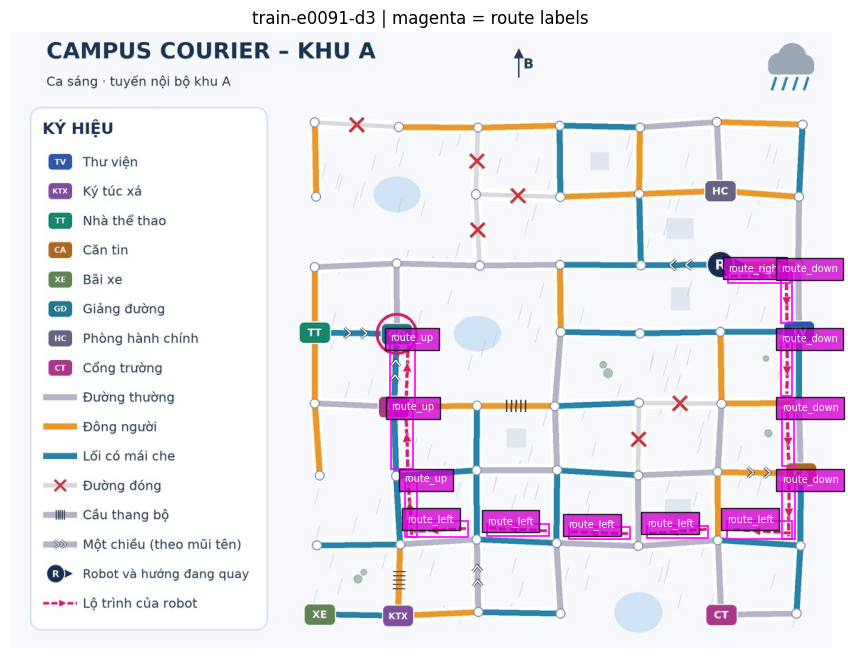

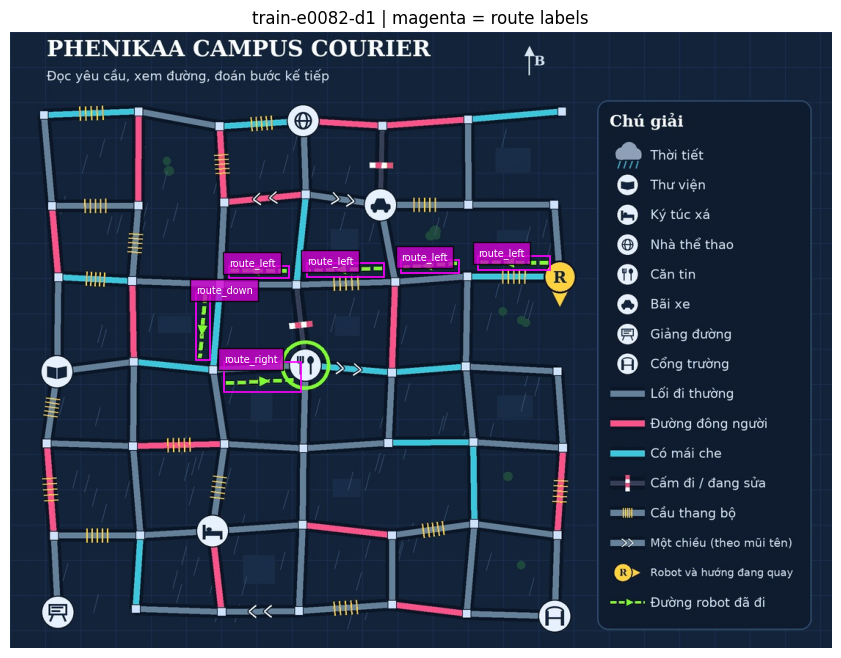

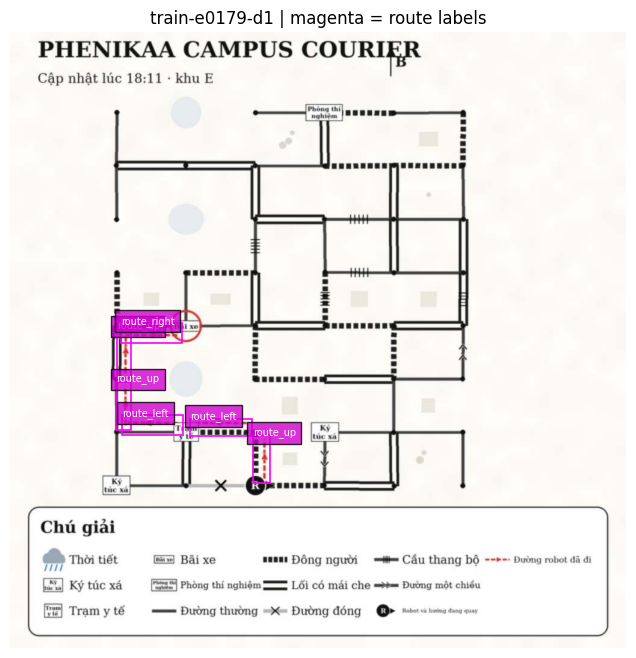

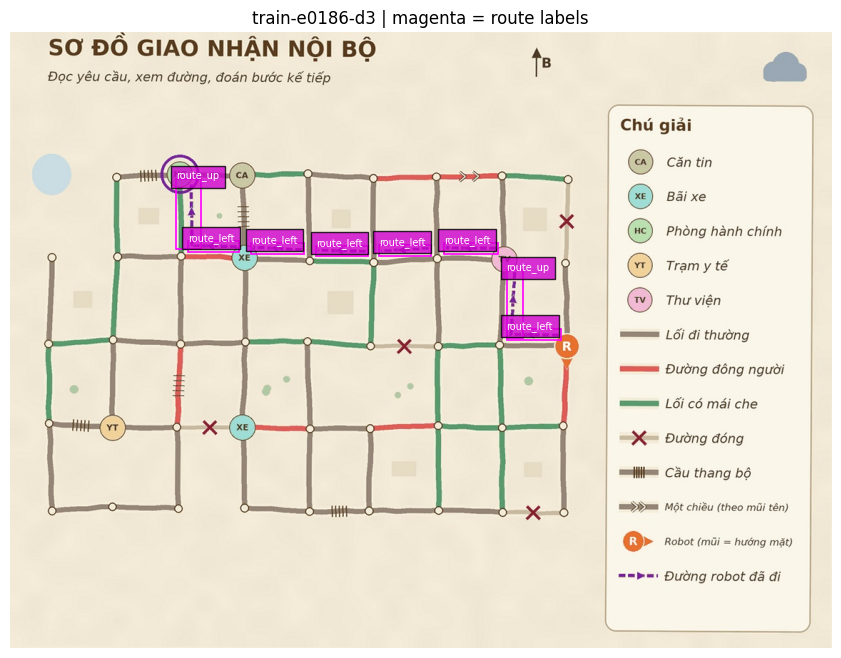

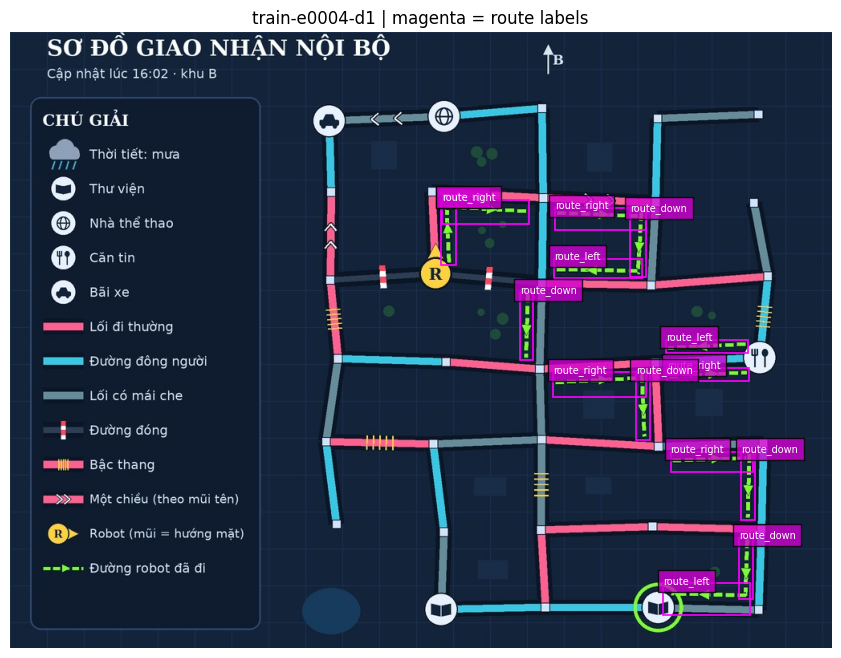

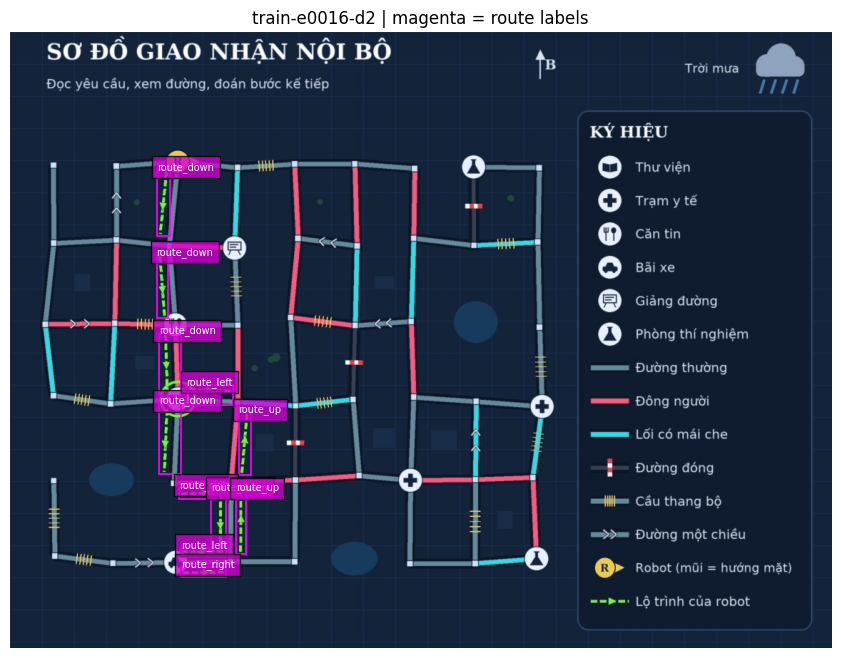

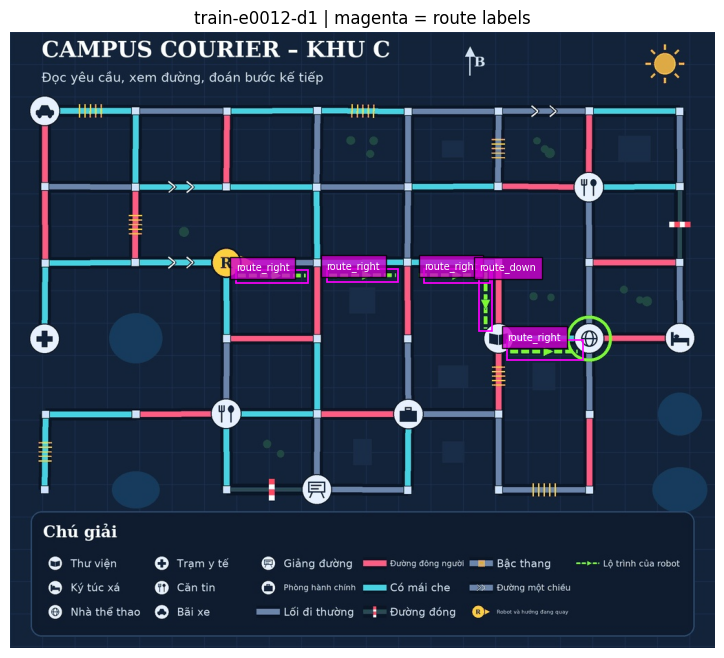

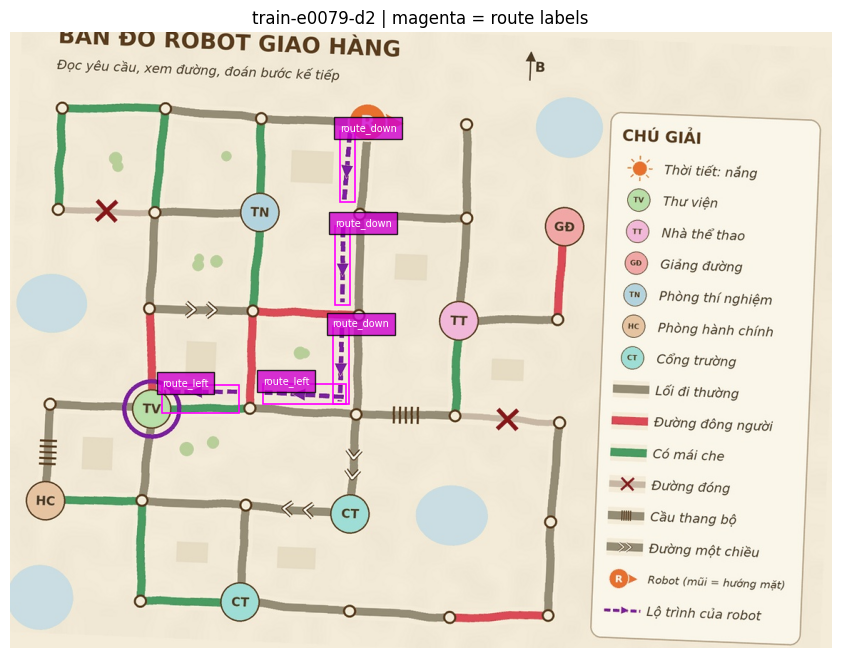

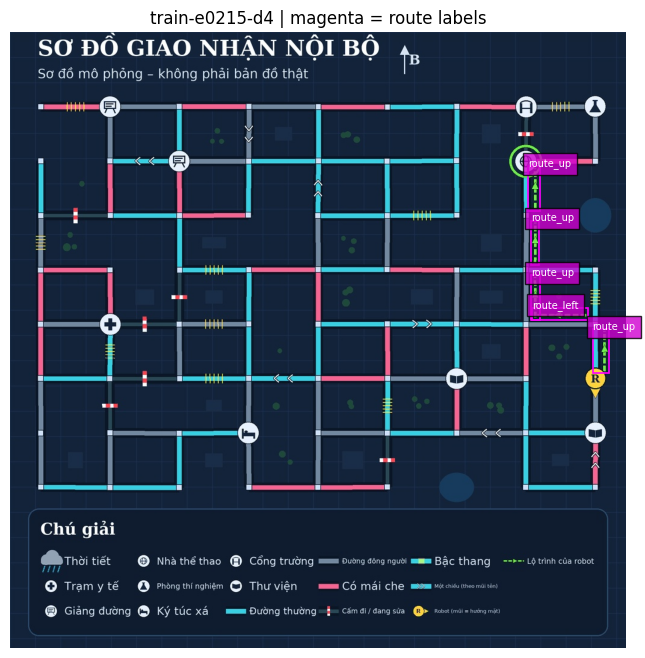

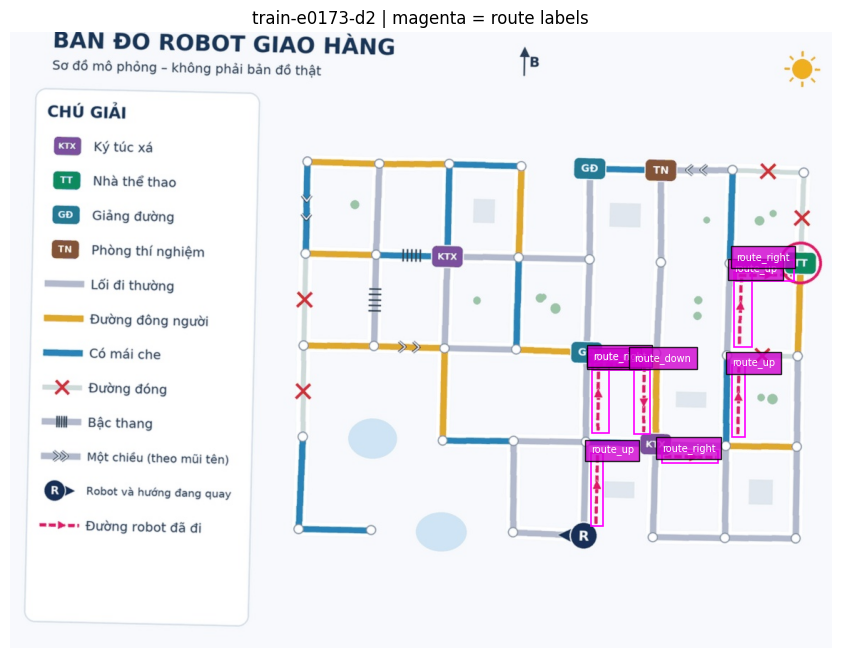

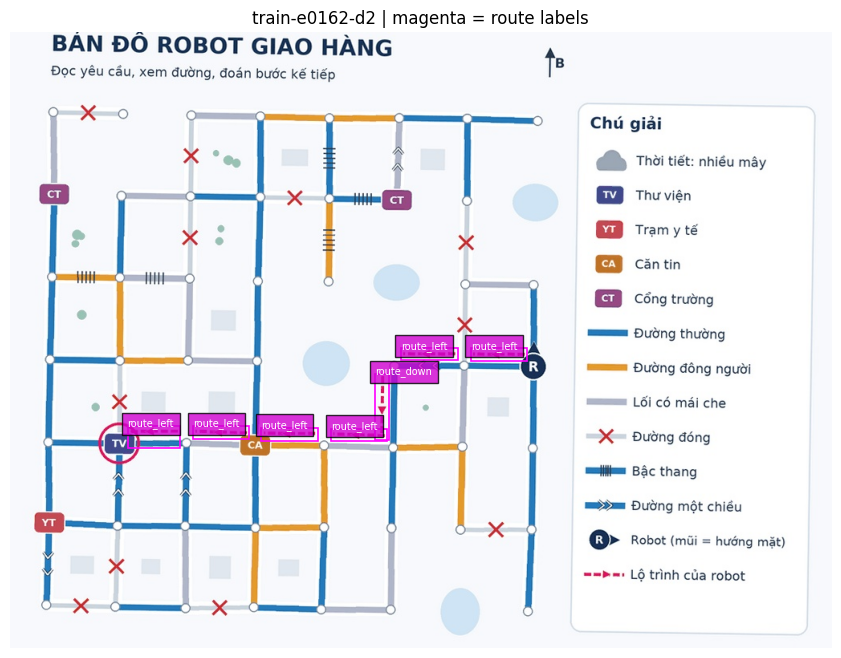

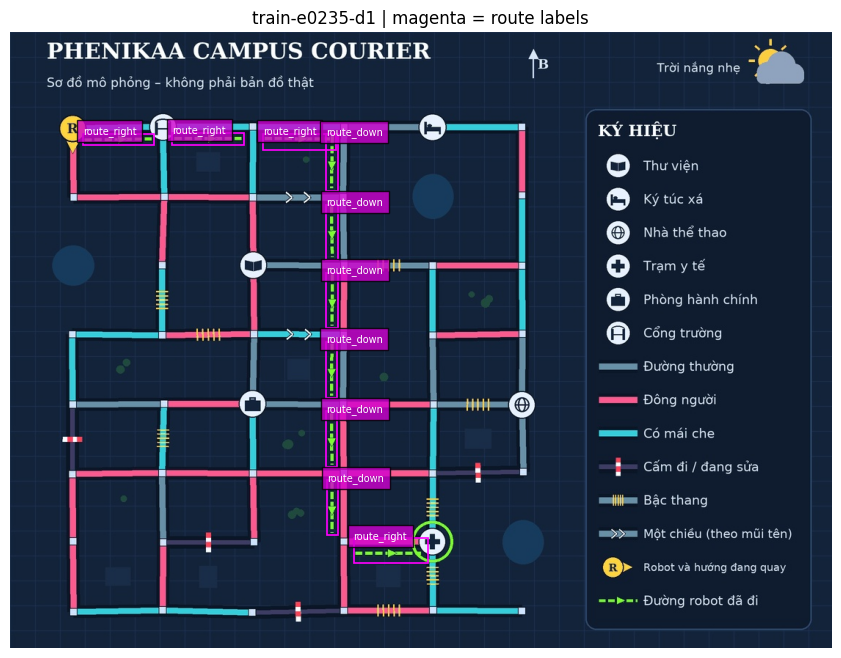

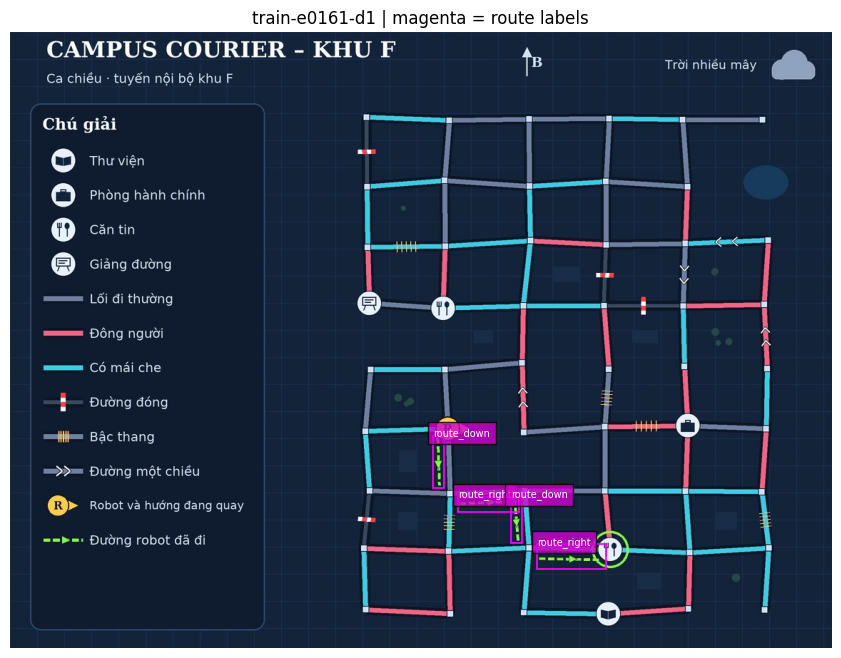

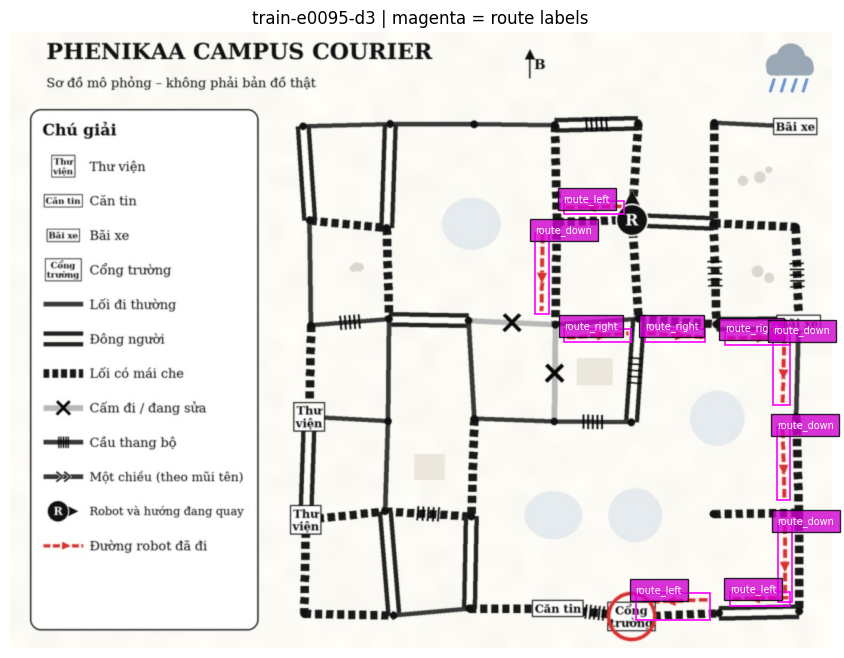

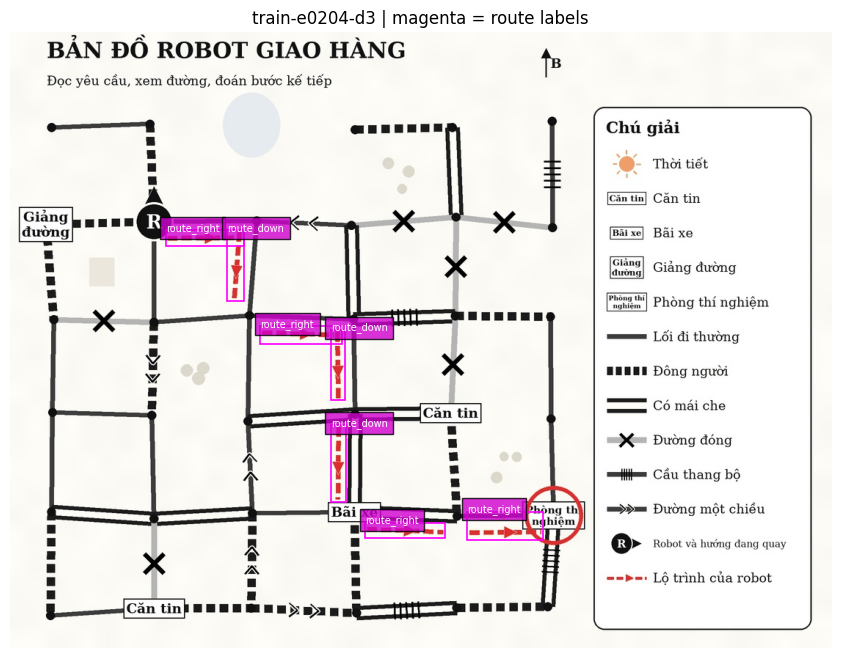

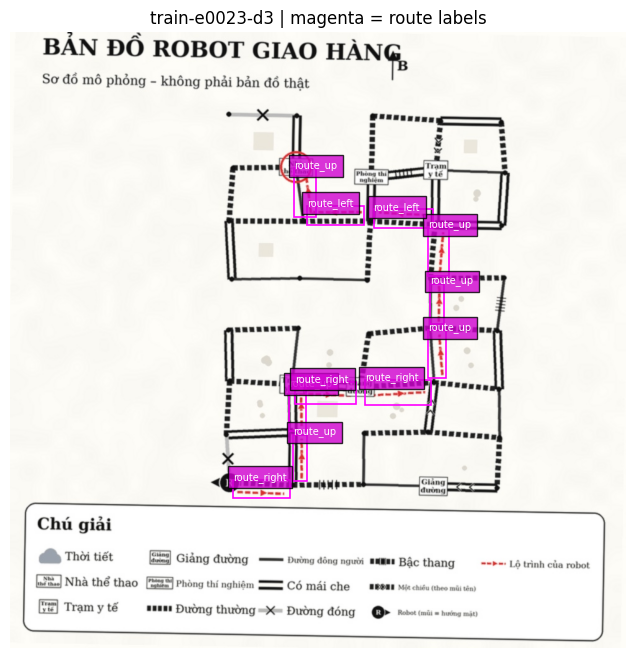

Kiểm tra box magenta có phủ nét/mũi tên lộ trình và không nhầm cạnh bên cạnh.


In [ ]:
# CELL 5 — QC tự động + xem bbox route trên ảnh demo
import random

def preview_route_labels(records,n=16,seed=SEED):
    candidates=[r for r in records if r['route_boxes']]
    if not candidates:
        raise RuntimeError('Không có route demo để QC.')
    rng=random.Random(seed)
    # Lấy mẫu đa dạng style trước, rồi bổ sung ngẫu nhiên.
    by_style={}
    for r in candidates: by_style.setdefault(r['scene'].get('style','?'),[]).append(r)
    chosen=[]
    for style,items in sorted(by_style.items()):
        if len(chosen)<n: chosen.append(rng.choice(items))
    rest=[r for r in candidates if r not in chosen]
    if len(chosen)<n: chosen.extend(rng.sample(rest,min(n-len(chosen),len(rest))))
    print('Styles có route:',{k:len(v) for k,v in by_style.items()},'| số ảnh xem:',len(chosen))
    for r in chosen:
        im=cv2.cvtColor(cv2.imread(str(r['image'])),cv2.COLOR_BGR2RGB)
        fig,ax=plt.subplots(figsize=(12,8)); ax.imshow(im)
        for cls_name,(x1,y1,x2,y2) in r['route_boxes']:
            ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color='#ff00ff',linewidth=1.2))
            ax.text(x1,y1,cls_name,color='white',fontsize=7,bbox={'facecolor':'#d000d0','alpha':.8})
        ax.set_title(f"{r['scene']['scene_id']} | magenta = route labels"); ax.axis('off'); plt.show()
preview_route_labels(TRAIN_RECORDS)
print('Kiểm tra box magenta có phủ nét/mũi tên lộ trình và không nhầm cạnh bên cạnh.')


## Duyệt nhãn trước khi train
Các tệp `route_label_qc` chưa được xác nhận nếu ảnh xem trước không khớp mũi tên thật. Nhãn route được suy từ tọa độ graph vì JSON không chứa bbox riêng. Chỉ đặt `APPROVE_ROUTE_LABEL_QC=True` sau khi kiểm tra đủ ảnh, cả các kiểu vẽ/style khác nhau. Không dùng validation để tạo thêm ảnh train.


In [ ]:
# CELL 6 — Fine-tune tiếp checkpoint YOLO đã có đủ 42 class
from pathlib import Path
import json
import shutil
import torch
from ultralytics import YOLO


model = YOLO(str("/content/runs/detect/yolo_map_route_42class/runs/yolov8m_map_route_42class/weights/best.pt"))

# Xác nhận model đã có đúng 42 class theo đúng thứ tự.
model_names = model.names
model_names = (
    [model_names[i] for i in range(len(model_names))]
    if isinstance(model_names, dict)
    else list(model_names)
)

if len(model_names) != 42:
    raise ValueError(
        f"Checkpoint có {len(model_names)} class, cần checkpoint 42 class."
    )

if model_names != CLASSES:
    raise ValueError(
        "Thứ tự class trong checkpoint không khớp CLASSES.\n"
        f"Model: {model_names}\n"
        f"Notebook: {CLASSES}"
    )

print("42 class OK; route IDs:", {
    name: i for i, name in enumerate(CLASSES) if name.startswith("route_")
})

import yaml

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

dataset_names = data_cfg["names"]
if isinstance(dataset_names, dict):
    dataset_names = [
        dataset_names[i] for i in range(len(dataset_names))
    ]

assert dataset_names == CLASSES, (
    f"DATA_YAML không khớp 42 class.\n"
    f"Dataset: {dataset_names}\n"
    f"Mong đợi: {CLASSES}"
)

print("Dataset YAML: đủ 42 class, đúng thứ tự.")

device = 0 if torch.cuda.is_available() else "cpu"
batch = BATCH_SIZE if torch.cuda.is_available() else 2

# Đây là một lượt fine-tune mới từ weights của best.pt,
# không phải resume optimizer của lần train cũ.
results = model.train(
    data=str(DATA_YAML),
    project=str(Path(OUTPUT_DIR) / "runs"),
    name="yolo_map_route_42class_finetune_pass2",
    exist_ok=False,

    epochs=25,
    patience=5,
    imgsz=IMGSZ,
    batch=batch,
    workers=WORKERS,
    seed=SEED,
    deterministic=True,

    optimizer="AdamW",
    lr0=0.00002,       # thấp hơn lượt train đầu để hạn chế quên kiến thức map
    lrf=0.10,
    cos_lr=True,
    warmup_epochs=1.0,
    weight_decay=0.0005,

    freeze=0,
    cls=2.0,
    box=6.0,
    dfl=1.5,

    # Không xoay/lật/làm méo bản đồ vì route và one-way có hướng tuyệt đối.
    fliplr=0.0,
    flipud=0.0,
    degrees=5.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,

    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    erasing=0.0,
    close_mosaic=0,

    hsv_h=0.05,
    hsv_s=0.05,
    hsv_v=0.08,

    cache=False,
    amp=torch.cuda.is_available(),
    save=True,
    save_period=5,
    plots=True,
    resume=False,
    device=device,
)

run_dir = Path(model.trainer.save_dir)
best_path = run_dir / "weights" / "best.pt"
last_path = run_dir / "weights" / "last.pt"

if not best_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy best checkpoint: {best_path}")

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

best_out = OUTPUT_DIR / "best_map_route_42class_pass2.pt"
shutil.copy2(best_path, best_out)

if last_path.is_file():
    shutil.copy2(
        last_path,
        OUTPUT_DIR / "last_map_route_42class_pass2.pt",
    )

(OUTPUT_DIR / "class_order_42class.json").write_text(
    json.dumps(CLASSES, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Fine-tune xong.")
print("Best pass 2:", best_out.resolve())
print("Run directory:", run_dir.resolve())

42 class OK; route IDs: {'route_up': 38, 'route_down': 39, 'route_left': 40, 'route_right': 41}
Dataset YAML: đủ 42 class, đúng thứ tự.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=6.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=2.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=yolo_map_route_42class/dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, hsv_h=0.05, hsv_s=0.05, hsv_v=0.08, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=2e-05, lrf=0.1, mask_ratio=4, max_det=300, mixup=

## Augmentation

Chỉ 5 ảnh demo mỗi episode được đưa vào train và validation. Train có thể tạo thêm hai biến thể ảnh nhẹ (blur, nhiễu/JPEG) từ chính ảnh demo để tăng độ bền; không lật/đảo/rotate vì sẽ đổi hướng tuyệt đối và one-way. Ảnh query không được giải nén, xuất nhãn hay đưa vào fine-tune.


## YOLO → graph: route là trạng thái thứ hai của cạnh

Mỗi cạnh giữ `status` đường (`normal`, `crowded`, `covered`, `closed`) độc lập với `route_status` (`route_up/down/left/right`). `route_edges` lưu cạnh có hướng; `route_moves`/`route_nodes` là đường đã ráp từ robot qua via tới goal nếu detections tạo thành chuỗi duy nhất/tốt nhất.


In [ ]:
import json
import math
import os
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from ultralytics import YOLO

# ==========================================
# CONFIG
# ==========================================
CLASSES = [
    'canteen', 'clinic', 'dorm', 'gate', 'lab', 'lecture', 'library', 'office', 'parking', 'sports',
    'robot_up', 'robot_down', 'robot_left', 'robot_right',
    'edge_type_1', 'edge_type_2', 'edge_type_3',
    'print_edge_1', 'print_edge_2', 'print_edge_3',
    'closed', 'stairs', 'oneway_up', 'oneway_down', 'oneway_left', 'oneway_right',
    'weather_sun', 'weather_cloud', 'weather_rain',
    'swatch_edge_1', 'swatch_edge_2', 'swatch_edge_3',
    'swatch_print_1', 'swatch_print_2', 'swatch_print_3',
    'txt_normal', 'txt_crowded', 'txt_covered',
    'route_up', 'route_down', 'route_left', 'route_right'
]

EDGE_CLS = ('edge_type_', 'print_edge_')                  # box cạnh (kiểu nét) -> status lấy từ legend
EDGE_BOX_CLS = {'closed'}                                 # closed = box phủ cả đoạn đường
MODIFIER_CLS = {'stairs', 'oneway_up', 'oneway_down', 'oneway_left', 'oneway_right'}  # icon nhỏ giữa cạnh
NODE_CLS = set(CLASSES[:14])                              # landmark + robot


# ==========================================
# HELPERS
# ==========================================
def get_center(box):
    return ((box[0] + box[2]) / 2, (box[1] + box[3]) / 2)


def get_distance(p1, p2):
    return math.sqrt((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2)


def dynamic_cluster(coords, unit_size):
    if not coords:
        return []
    coords = sorted(coords)
    clusters = [[coords[0]]]
    tolerance = unit_size * 0.4
    for c in coords[1:]:
        if c - np.mean(clusters[-1]) <= tolerance:
            clusters[-1].append(c)
        else:
            clusters.append([c])
    return [float(np.mean(cl)) for cl in clusters]


def get_grid_index(val, clusters):
    return min(range(len(clusters)), key=lambda i: abs(clusters[i] - val))


def is_plain_edge(c):
    return c.startswith(EDGE_CLS)


# ==========================================
# LEGEND: swatch k -> txt bên cạnh -> status
# ==========================================
def build_legend(dets, txt_side='right', pairs_out=None):
    texts = [d for d in dets if d['class'].startswith('txt_')]
    swatches = [d for d in dets if d['class'].startswith(('swatch_edge_', 'swatch_print_'))]
    if not texts or not swatches:
        return {}

    def find_label(s):
        sx1, _, sx2, _ = s['box']
        slack = 0.3 * s['w']
        row = [t for t in texts
               if abs(t['center'][1] - s['center'][1]) <= max(s['h'], t['h']) * 0.6]
        if txt_side == 'left':
            side = [t for t in row if t['box'][2] <= sx1 + slack]
        else:
            side = [t for t in row if t['box'][0] >= sx2 - slack]
        pool = side or row or texts
        return min(pool, key=lambda t: get_distance(t['center'], s['center']))

    best = {}  # k -> (conf swatch, status)
    for s in swatches:
        k = s['class'][-1]
        t = find_label(s)
        if pairs_out is not None:
            pairs_out.append((s, t))
        status = t['class'].replace('txt_', '')
        if k not in best or s['conf'] > best[k][0]:
            best[k] = (s['conf'], status)

    legend = {}
    for k, (_, status) in best.items():
        legend['edge_type_' + k] = status
        legend['print_edge_' + k] = status
    return legend


def _oneway_target(direction, na, nb):
    if direction == 'up':
        return [min(na[0], nb[0]), na[1]]
    if direction == 'down':
        return [max(na[0], nb[0]), na[1]]
    if direction == 'left':
        return [na[0], min(na[1], nb[1])]
    return [na[0], max(na[1], nb[1])]  # right


# ==========================================
# 1. YOLO -> DETS (chạy model 1 lần, lọc ngưỡng sau)
# ==========================================
def predict_dets(model, image_path, min_conf=0.1):
    res = model.predict(image_path, conf=min_conf, verbose=False)[0]
    img = res.orig_img[:, :, ::-1]  # BGR -> RGB
    dets = []
    for box, cls_id, cf in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.cls.cpu().numpy(),
                               res.boxes.conf.cpu().numpy()):
        box = [float(v) for v in box]
        dets.append({'class': CLASSES[int(cls_id)], 'box': box, 'conf': float(cf),
                     'center': get_center(box), 'w': box[2] - box[0], 'h': box[3] - box[1]})
    return dets, img


def collect_dets(model, scenes, img_dir, min_conf=0.1):
    """Chạy YOLO trên toàn bộ val 1 lần, trả {scene_id: dets}. Sau đó thử ngưỡng khác không cần chạy lại model."""
    cache = {}
    for sc in tqdm(scenes, desc="YOLO predict"):
        path = os.path.join(img_dir, f"{sc['scene_id']}.jpg")
        if os.path.exists(path):
            cache[sc['scene_id']] = predict_dets(model, path, min_conf)[0]
    return cache


# ==========================================
# 2. DETS -> JSON GRAPH
#    box cạnh   : edge_type_k / print_edge_k (status = legend) / closed
#    icon nhỏ   : stairs / oneway_*  -> gán vào cạnh có box chứa tâm icon
#    split_long : box cạnh dài >1 ô -> tách thành nhiều cạnh 1 ô (False = giữ kiểu cũ: 1 cạnh nối xa)
# ==========================================
def dets_to_scene(dets, mission_via=None, mission_goal=None, conf=0.4, edge_conf=None,
                  txt_side='right', split_long=True, trace=None, route_conf=None,
                  mission_via_rc=None, mission_goal_rc=None):
    edge_conf = conf if edge_conf is None else edge_conf
    route_conf = conf if route_conf is None else route_conf
    dets = [dict(d) for d in dets
            if d['conf'] >= (edge_conf if is_plain_edge(d['class']) else route_conf if d['class'].startswith('route_') else conf)]

    pairs = []
    legend = build_legend(dets, txt_side=txt_side, pairs_out=pairs)
    for d in dets:
        if is_plain_edge(d['class']):
            d['status'] = legend.get(d['class'], '?')

    edge_dets = [d for d in dets if is_plain_edge(d['class']) or d['class'] in EDGE_BOX_CLS]
    modifiers = [d for d in dets if d['class'] in MODIFIER_CLS]

    # thước đo ô lưới: chỉ đo trên box cạnh (không tính icon)
    hw = [d['w'] for d in edge_dets if d['w'] > d['h']]
    vh = [d['h'] for d in edge_dets if d['h'] > d['w']]
    grid_w = float(np.median(hw)) if hw else 100.0
    grid_h = float(np.median(vh)) if vh else 100.0

    scene = {'nodes': [], 'edges': [], 'landmarks': [], 'robot': {},
             'weather': 'rain' if any(d['class'] == 'weather_rain' for d in dets) else 'dry',
             'mission': {'via': mission_via, 'goal': mission_goal}, 'warnings': []}

    # --- lưới động
    raw_x, raw_y = [], []
    for d in dets:
        if d['class'] in NODE_CLS:
            raw_x.append(d['center'][0])
            raw_y.append(d['center'][1])
    for d in edge_dets:
        x1, y1, x2, y2 = d['box']
        if d['w'] >= d['h']:
            raw_y.append(d['center'][1])
            raw_x += [x1, x2]
        else:
            raw_x.append(d['center'][0])
            raw_y += [y1, y2]
    col_cl, row_cl = dynamic_cluster(raw_x, grid_w), dynamic_cluster(raw_y, grid_h)

    # --- landmark / robot
    for d in dets:
        if d['class'] not in NODE_CLS:
            continue
        r, c = get_grid_index(d['center'][1], row_cl), get_grid_index(d['center'][0], col_cl)
        if d['class'].startswith('robot_'):
            scene['robot'] = {'rc': [r, c], 'heading': d['class'].split('_')[1].upper()}
        else:
            scene['landmarks'].append({'type': d['class'], 'rc': [r, c]})
    for r in range(len(row_cl)):
        for c in range(len(col_cl)):
            scene['nodes'].append({'rc': [r, c]})

    # --- cạnh
    edges = {}
    for d in edge_dets:
        x1, y1, x2, y2 = d['box']
        horiz = d['w'] >= d['h']
        if horiz:
            r = get_grid_index(d['center'][1], row_cl)
            ca, cb = sorted([get_grid_index(x1, col_cl), get_grid_index(x2, col_cl)])
            steps = [([r, c], [r, c + 1]) for c in range(ca, cb)]
        else:
            c = get_grid_index(d['center'][0], col_cl)
            ra, rb = sorted([get_grid_index(y1, row_cl), get_grid_index(y2, row_cl)])
            steps = [([r, c], [r + 1, c]) for r in range(ra, rb)]
        if not steps:
            continue
        if len(steps) > 1:
            scene['warnings'].append(f"{d['class']} dai {len(steps)} o: {steps[0][0]}->{steps[-1][1]}"
                                     f" ({'tach' if split_long else 'giu nguyen'})")
            if not split_long:
                steps = [(steps[0][0], steps[-1][1])]

        for na, nb in steps:
            if horiz:
                box = [col_cl[na[1]], y1, col_cl[nb[1]], y2]
            else:
                box = [x1, row_cl[na[0]], x2, row_cl[nb[0]]]
            key = (tuple(na), tuple(nb))
            e = edges.setdefault(key, {'a': na, 'b': nb, 'status': None, 'stairs': False,
                                       'oneway_to': None, 'route_status': None, 'route_statuses': [], 'route_to': None, '_box': box, '_horiz': horiz,
                                       '_center': get_center(box), '_plain_conf': -1.0,
                                       '_closed': False, '_src': None})
            cls = d['class']
            if is_plain_edge(cls):
                if d['conf'] > e['_plain_conf']:      # 2 box plain chồng nhau -> lấy box conf cao hơn
                    e['_plain_conf'] = d['conf']
                    e['status'] = legend.get(cls, 'normal')
                    e['_src'] = ('legend:' if cls in legend else 'NO_LEGEND:') + cls
            else:  # closed
                e['_closed'] = True

    for e in edges.values():
        if e['_closed']:
            e['status'] = 'closed'
            e['_src'] = 'closed_box'

    # --- icon nhỏ -> cạnh có box chứa tâm icon, đúng hướng
    tol = 0.15 * min(grid_w, grid_h)
    for m in modifiers:
        cx, cy = m['center']
        direction = m['class'].split('_')[1] if m['class'].startswith('oneway_') else None
        best, best_d = None, None
        for e in edges.values():
            x1, y1, x2, y2 = e['_box']
            if not (x1 - tol <= cx <= x2 + tol and y1 - tol <= cy <= y2 + tol):
                continue
            if direction in ('left', 'right') and not e['_horiz']:
                continue
            if direction in ('up', 'down') and e['_horiz']:
                continue
            dist = get_distance(m['center'], e['_center'])
            if best is None or dist < best_d:
                best, best_d = e, dist
        if best is None:
            scene['warnings'].append(f"icon {m['class']} tai {np.round(m['center']).tolist()} khong nam trong canh nao")
            continue
        if m['class'] == 'stairs':
            best['stairs'] = True
        else:
            best['oneway_to'] = _oneway_target(direction, best['a'], best['b'])

    # Route classes are a second edge status; keep road status unchanged.
    route_dirs={'route_up':(-1,0),'route_down':(1,0),'route_left':(0,-1),'route_right':(0,1)}
    route_edges=[]
    for rd in [d for d in dets if d['class'] in route_dirs]:
        dr,dc=route_dirs[rd['class']]
        best=None; best_dist=float('inf')
        for e in edges.values():
            a,b=tuple(e['a']),tuple(e['b'])
            if (b[0]-a[0],b[1]-a[1])==(dr,dc): src,dst=a,b
            elif (a[0]-b[0],a[1]-b[1])==(dr,dc): src,dst=b,a
            else: continue
            p0=np.array([col_cl[src[1]],row_cl[src[0]]],float)
            p1=np.array([col_cl[dst[1]],row_cl[dst[0]]],float)
            vec=p1-p0; L=float(np.linalg.norm(vec))
            if L<2: continue
            u=vec/L; right=np.array([-u[1],u[0]])
            expected=p0+ROUTE_CENTER_T*vec+ROUTE_LANE_OFFSET_RATIO*L*right
            # Normalize by cell pitch so skewed/hard maps share a scale.
            pitch=max(1.0,min(grid_w,grid_h))
            dist=float(np.linalg.norm(np.asarray(rd['center'],float)-expected))/pitch
            if dist<best_dist: best_dist=dist; best=(src,dst,e)
        if best is None or best_dist>0.45:
            scene['warnings'].append(f"{rd['class']} không ghép được cạnh route (normalized_error={best_dist:.3f})")
            continue
        src,dst,e=best; direction=rd['class'].replace('route_','')
        e['route_statuses'].append(rd['class'])
        # route_status is separate from road status and supports both directions on one road.
        unique=sorted(set(e['route_statuses']))
        e['route_statuses']=unique
        e['route_status']=unique[0] if len(unique)==1 else 'multiple'
        e['route_to']=list(dst) if len(unique)==1 else None
        route_edges.append({'from':list(src),'to':list(dst),'direction':direction,
                            'class':rd['class'],'confidence':float(rd['conf']),
                            'offset_error_cells':best_dist,'edge_status':e.get('status')})
    scene['route_edges']=route_edges
    goal_ref=scene.get('mission',{}).get('goal')
    via_ref=scene.get('mission',{}).get('via')
    goal_targets=[tuple(mission_goal_rc)] if mission_goal_rc is not None else [tuple(l['rc']) for l in scene['landmarks'] if l['type']==mission_goal]
    via_targets=[tuple(mission_via_rc)] if mission_via_rc is not None else [tuple(l['rc']) for l in scene['landmarks'] if l['type']==mission_via]
    if mission_via is None: via_targets=[]
    rec=reconstruct_route(route_edges,scene.get('robot',{}).get('rc'),goal_targets,via_targets,max_steps=45)
    scene['route_moves']=rec['moves']
    scene['route_nodes']=rec['nodes']
    scene['route_reconstruction']={'ok':rec['ok'],'ambiguous':rec['ambiguous'],
                                   'used_edges':rec['used_edges'],'detected_edges':len(route_edges),
                                   'reason':rec['reason']}
    if not rec['ok']:
        scene['warnings'].append('Không ráp được route đầy đủ: '+rec['reason'])
    if trace is not None:
        trace['route_edges']=route_edges
        trace['route_reconstruction']=scene['route_reconstruction']
    for e in edges.values():
        e['route_statuses']=sorted(set(e.get('route_statuses',[])))
        for k in ('_box', '_horiz', '_center', '_plain_conf', '_closed', '_src'):
            e.pop(k, None)
        scene['edges'].append(e)
    return scene


# Thay toàn bộ reconstruct_route hiện tại bằng hàm này
import heapq
import math

def reconstruct_route(
    route_edges,
    start,
    goal_targets,
    via_targets=None,
    max_steps=45,
    beam_size=None,  # giữ tham số để tương thích với các chỗ gọi cũ
):
    """Tìm route chi phí thấp nhất từ robot → via (nếu có) → goal."""
    if start is None:
        return {
            "ok": False, "moves": [], "nodes": [],
            "ambiguous": False, "used_edges": 0,
            "reason": "missing_robot",
        }

    start = tuple(int(x) for x in start)
    goals = {tuple(int(x) for x in x) for x in (goal_targets or [])}
    vias = {tuple(int(x) for x in x) for x in (via_targets or [])}

    if not route_edges:
        return {
            "ok": False, "moves": [], "nodes": [list(start)],
            "ambiguous": False, "used_edges": 0,
            "reason": "no_route_detections",
        }

    if not goals:
        return {
            "ok": False, "moves": [], "nodes": [list(start)],
            "ambiguous": False, "used_edges": 0,
            "reason": "goal_not_resolved",
        }

    # Nối các phát hiện cùng cạnh có hướng; giữ phát hiện có chi phí thấp nhất.
    # Tọa độ quyết định hướng bước, tránh phụ thuộc chuỗi direction.
    direction_to_move = {
        (-1, 0): 0,  # UP
        (1, 0): 1,   # DOWN
        (0, -1): 2,  # LEFT
        (0, 1): 3,   # RIGHT
    }

    edge_by_key = {}
    for edge in route_edges:
        try:
            a = tuple(int(x) for x in edge["from"])
            b = tuple(int(x) for x in edge["to"])
        except (KeyError, TypeError, ValueError):
            continue

        delta = (b[0] - a[0], b[1] - a[1])
        if delta not in direction_to_move:
            continue

        confidence = max(
            1e-5,
            min(1.0, float(edge.get("confidence", 0.5))),
        )
        offset_error = max(
            0.0,
            min(2.0, float(edge.get("offset_error_cells", 0.0))),
        )

        # Mỗi bước có chi phí cơ bản 1.0 để tránh route vòng.
        # Confidence và sai lệch hình học chỉ phân biệt các route gần ngang nhau.
        edge_cost = (
            1.0
            + 0.25 * (1.0 - confidence)
            + 0.25 * offset_error
        )

        key = (a, b)
        old = edge_by_key.get(key)
        if old is None or edge_cost < old["cost"]:
            edge_by_key[key] = {
                "from": a,
                "to": b,
                "move": direction_to_move[delta],
                "cost": edge_cost,
            }

    adjacency = {}
    for edge in edge_by_key.values():
        adjacency.setdefault(edge["from"], []).append(edge)

    initial_via_seen = (not vias) or (start in vias)
    start_state = (start, initial_via_seen)

    # Dijkstra trên trạng thái (node, đã ghé via chưa).
    best = {start_state: (0.0, 0)}
    parent = {}
    heap = [(0.0, 0, start, initial_via_seen)]
    final_state = None

    while heap:
        cost, steps, node, via_seen = heapq.heappop(heap)
        state = (node, via_seen)

        if (cost, steps) != best.get(state):
            continue

        # Dừng tại goal đầu tiên sau khi đã ghé via.
        if node in goals and via_seen and steps > 0:
            final_state = state
            break

        if steps >= max_steps:
            continue

        for edge in adjacency.get(node, []):
            nxt = edge["to"]
            next_via_seen = via_seen or (nxt in vias)
            next_state = (nxt, next_via_seen)

            new_cost = cost + edge["cost"]
            new_steps = steps + 1
            candidate = (new_cost, new_steps)

            if candidate < best.get(next_state, (math.inf, math.inf)):
                best[next_state] = candidate
                parent[next_state] = (state, edge)
                heapq.heappush(
                    heap,
                    (new_cost, new_steps, nxt, next_via_seen),
                )

    if final_state is None:
        return {
            "ok": False,
            "moves": [],
            "nodes": [list(start)],
            "ambiguous": False,
            "used_edges": 0,
            "reason": "no directed route from robot through via to goal",
        }

    # Lần ngược trạng thái để dựng route.
    moves_reversed = []
    nodes_reversed = [final_state[0]]
    used_edges = set()
    state = final_state

    while state != start_state:
        if state not in parent:
            return {
                "ok": False, "moves": [], "nodes": [list(start)],
                "ambiguous": False, "used_edges": 0,
                "reason": "broken_parent_chain",
            }

        previous_state, edge = parent[state]
        moves_reversed.append(edge["move"])
        nodes_reversed.append(previous_state[0])
        used_edges.add((edge["from"], edge["to"]))
        state = previous_state

    moves = list(reversed(moves_reversed))
    nodes = [list(node) for node in reversed(nodes_reversed)]

    return {
        "ok": True,
        "moves": moves,
        "nodes": nodes,
        "ambiguous": False,
        "used_edges": len(used_edges),
        "reason": "ok",
    }


def yolo_to_scene_json(image_path, model, mission_via=None, mission_goal=None, conf=0.4,
                       edge_conf=None, split_long=True, txt_side='right', trace=None, route_conf=None,
                       mission_via_rc=None, mission_goal_rc=None):
    model = YOLO(model) if isinstance(model, str) else model
    dets, img = predict_dets(model, image_path, min_conf=min(conf, edge_conf or conf, route_conf or conf))
    scene = dets_to_scene(dets, mission_via, mission_goal, conf, edge_conf, txt_side, split_long, trace,
                          route_conf=route_conf, mission_via_rc=mission_via_rc, mission_goal_rc=mission_goal_rc)
    if trace is not None:
        trace['img'] = img
    return scene


# ==========================================
# 3. SO SÁNH VỚI GROUND TRUTH
# ==========================================
def _edge_dict(scene):
    out = {}
    for e in scene.get('edges', []):
        k = tuple(sorted([tuple(e['a']), tuple(e['b'])]))
        ow = tuple(e['oneway_to']) if e.get('oneway_to') else None
        out[k] = {'status': e.get('status', 'normal'), 'stairs': bool(e.get('stairs')), 'oneway_to': ow}
    return out


def compare_scenes(pred, true, edge_src=None):
    """Trả (errors, counts). errors: list dict {type, key, pred, true, src}."""
    edge_src = edge_src or {}
    errors = []
    P, T = _edge_dict(pred), _edge_dict(true)

    def src_of(k):
        # edge_src key = (a, b) đã sort sẵn
        return (edge_src.get(k) or '-').split(':')[0]

    n_correct = 0
    for k in sorted(set(P) | set(T)):
        p, t = P.get(k), T.get(k)
        if p is None:
            errors.append({'type': 'edge_missing', 'key': k, 'pred': None, 'true': t, 'src': '-'})
        elif t is None:
            errors.append({'type': 'edge_extra', 'key': k, 'pred': p, 'true': None, 'src': src_of(k)})
        else:
            ok = True
            for field, etype in (('status', 'edge_wrong_status'), ('stairs', 'edge_wrong_stairs'),
                                 ('oneway_to', 'edge_wrong_oneway_to')):
                if p[field] != t[field]:
                    ok = False
                    errors.append({'type': etype, 'key': k, 'pred': p[field], 'true': t[field],
                                   'src': src_of(k)})
            n_correct += ok

    lm_p = {(lm['type'], tuple(lm['rc'])) for lm in pred.get('landmarks', [])}
    lm_t = {(lm['type'], tuple(lm['rc'])) for lm in true.get('landmarks', [])}
    for x in sorted(lm_t - lm_p):
        errors.append({'type': 'landmark_missing', 'key': x, 'pred': None, 'true': x, 'src': '-'})
    for x in sorted(lm_p - lm_t):
        errors.append({'type': 'landmark_extra', 'key': x, 'pred': x, 'true': None, 'src': '-'})

    def rob(sc):
        r = sc.get('robot') or {}
        return (tuple(r['rc']), r.get('heading', '').upper()) if r.get('rc') else None
    if rob(pred) != rob(true):
        errors.append({'type': 'robot_wrong', 'key': 'robot', 'pred': rob(pred), 'true': rob(true), 'src': '-'})

    def wea(sc):
        return 'dry' if sc.get('weather', 'dry') == 'dry' else 'rain'
    if wea(pred) != wea(true):
        errors.append({'type': 'weather_wrong', 'key': 'weather', 'pred': wea(pred), 'true': wea(true), 'src': '-'})

    return errors, {'gt_edges': len(T), 'pred_edges': len(P), 'edge_correct': n_correct}


# ==========================================
# 4. QUÉT TOÀN BỘ VAL
# ==========================================
def evaluate_val(scenes, dets_cache, conf=0.4, edge_conf=None, split_long=True, txt_side='right',
                 quiet=False, max_list=80, save_path=None):
    n_img = n_exact = 0
    tot = Counter()
    err_types = Counter()
    status_conf = Counter()      # (pred -> true) cho edge_wrong_status
    status_src = Counter()       # nguồn status của cạnh bị sai status
    failures = {}

    for sc in scenes:
        sid = sc['scene_id']
        if sid not in dets_cache:
            continue
        trace = {}
        pred = dets_to_scene(dets_cache[sid], sc['mission'].get('via'), sc['mission'].get('goal'),
                             conf=conf, edge_conf=edge_conf, txt_side=txt_side,
                             split_long=split_long, trace=trace)
        errs, cnt = compare_scenes(pred, sc, trace['edge_src'])
        n_img += 1
        tot.update(cnt)
        if not errs:
            n_exact += 1
            continue
        for e in errs:
            err_types[e['type']] += 1
            if e['type'] == 'edge_wrong_status':
                status_conf[(e['pred'], e['true'])] += 1
                status_src[e['src']] += 1
        failures[sid] = [{**e, 'key': str(e['key']), 'pred': str(e['pred']), 'true': str(e['true'])}
                         for e in errs]

    rec = tot['edge_correct'] / max(tot['gt_edges'], 1)
    prec = tot['edge_correct'] / max(tot['pred_edges'], 1)
    summary = {'images': n_img, 'exact': n_exact, 'exact_rate': n_exact / max(n_img, 1),
               'edge_recall': rec, 'edge_precision': prec, 'errors': dict(err_types)}

    if not quiet:
        print("=" * 64)
        print(f"conf={conf} edge_conf={edge_conf} split_long={split_long}")
        print(f"DUNG HOAN TOAN : {n_exact}/{n_img} anh ({100 * n_exact / max(n_img, 1):.1f}%)  | SAI: {n_img - n_exact} anh")
        print(f"Canh dung nguyen ven: {tot['edge_correct']}/{tot['gt_edges']} GT "
              f"(recall {100 * rec:.2f}%) | {tot['pred_edges']} canh du doan (precision {100 * prec:.2f}%)")
        print("\nLoai loi:")
        for k, v in err_types.most_common():
            print(f"  {k:<24}{v}")
        if status_conf:
            print("\nedge_wrong_status  (pred -> true):")
            for (p, t), v in status_conf.most_common():
                print(f"  {p:>8} -> {t:<8} {v}")
            print("nguon status cua cac canh sai (NO_LEGEND = thieu legend, legend = model phan loai sai net):")
            for k, v in status_src.most_common():
                print(f"  {k:<14}{v}")
        print("\nDANH SACH ANH SAI:")
        for sid in sorted(failures)[:max_list]:
            print(f"[{sid}] ({len(failures[sid])} loi)")
            for e in failures[sid]:
                print(f"   - {e['type']}: {e['key']} pred={e['pred']} true={e['true']}")
        if len(failures) > max_list:
            print(f"... con {len(failures) - max_list} anh nua (xem file json)")
    if save_path:
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(failures, f, ensure_ascii=False, indent=1)
        if not quiet:
            print(f"\nDa luu chi tiet vao {save_path}")
    return summary


def sweep(scenes, dets_cache, configs):
    """configs: list (ten, dict kwargs cho evaluate_val). Chi hau xu ly, khong chay lai YOLO."""
    print(f"{'config':<28}{'exact':>10}{'recall':>9}{'prec':>9}   loi")
    for name, kw in configs:
        s = evaluate_val(scenes, dets_cache, quiet=True, **kw)
        n_err = sum(s['errors'].values())
        print(f"{name:<28}{s['exact']:>4}/{s['images']:<5}{100 * s['edge_recall']:>8.2f}%"
              f"{100 * s['edge_precision']:>8.2f}%   {n_err}")


# ==========================================
# 5. VẼ (debug 1 ảnh)
# ==========================================
def show_labeled_detections(trace, figsize=(18, 18)):
    COL = {'normal': 'limegreen', 'crowded': 'red', 'covered': 'blue', '?': 'magenta'}
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(trace['img'])
    for d in trace['dets']:
        cls = d['class']
        x1, y1, x2, y2 = d['box']
        if is_plain_edge(cls):
            st = d.get('status', '?')
            color = COL.get(st, 'magenta')
            tag = cls.replace('print_edge_', 'p').replace('edge_type_', 'e') + '=' + st
            tx, ty, va = (x1 + x2) / 2, (y1 + y2) / 2, 'center'
        elif cls.startswith(('swatch_', 'txt_')):
            color, tag, tx, ty, va = 'red', f"{cls} {d['conf']:.2f}", x1, y1 - 2, 'bottom'
        elif cls in MODIFIER_CLS or cls == 'closed':
            color, tag, tx, ty, va = 'darkorange', cls, x1, y1 - 2, 'bottom'
        elif cls.startswith('weather_'):
            color, tag, tx, ty, va = 'gray', cls, x1, y1 - 2, 'bottom'
        else:
            color, tag, tx, ty, va = 'cyan', cls, x1, y1 - 2, 'bottom'
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=1.3))
        ax.text(tx, ty, tag, color=color, fontsize=7, ha='center' if va == 'center' else 'left', va=va,
                fontweight='bold', bbox=dict(facecolor='white', alpha=0.65, pad=0.5, edgecolor='none'))
    for s, t in trace['pairs']:
        ax.annotate('', xy=t['center'], xytext=s['center'], arrowprops=dict(arrowstyle='->', color='lime', lw=2))
    ax.set_title("DETECTION + LABEL (e/p = edge_type/print_edge, sau dau '=' la status theo legend)")
    ax.axis('off')
    plt.tight_layout()
    plt.show()


def draw_scene_map(scene, title="Scene Map", ax=None, highlight=None):
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(10, 10))
    ax.set_title(title, fontsize=14, fontweight='bold')
    highlight = highlight or set()

    def get_xy(rc):
        return rc[1], -rc[0]

    color_map = {'normal': 'black', 'crowded': 'red', 'covered': 'blue', 'closed': 'gray'}
    style_map = {'normal': '-', 'crowded': '--', 'covered': ':', 'closed': '-.'}

    for edge in scene.get('edges', []):
        x1, y1 = get_xy(edge['a'])
        x2, y2 = get_xy(edge['b'])
        st = edge.get('status', 'normal')
        ax.plot([x1, x2], [y1, y2], color=color_map.get(st, 'black'),
                linestyle=style_map.get(st, '-'), linewidth=3, alpha=0.7, zorder=1)
        mx, my = (x1 + x2) / 2, (y1 + y2) / 2
        key = tuple(sorted([tuple(edge['a']), tuple(edge['b'])]))
        if key in highlight:
            ax.plot([x1, x2], [y1, y2], color='magenta', linewidth=11, alpha=0.3, zorder=0)
            ax.text(mx, my + 0.12, st, color='magenta', fontsize=9, ha='center', fontweight='bold', zorder=6)
        if st == 'closed':
            ax.text(mx, my, 'X', color='darkred', fontsize=16, fontweight='bold', ha='center', va='center', zorder=3)
        if edge.get('stairs'):
            ax.text(mx, my, '|||', color='orange', fontsize=14, fontweight='bold', ha='center', va='center', zorder=3)
        if edge.get('oneway_to'):
            tx, ty = get_xy(edge['oneway_to'])
            other = edge['a'] if tuple(edge['oneway_to']) == tuple(edge['b']) else edge['b']
            ox, oy = get_xy(other)
            ux, uy = (tx - ox), (ty - oy)
            ax.annotate('', xy=(mx + ux * 0.2, my + uy * 0.2), xytext=(mx - ux * 0.2, my - uy * 0.2),
                        arrowprops=dict(arrowstyle='-|>', color='green', lw=3), zorder=4)

    for lm in scene.get('landmarks', []):
        x, y = get_xy(lm['rc'])
        ax.scatter(x, y, s=600, c='lightgreen', edgecolors='green', zorder=4)
        ax.text(x, y + 0.25, lm['type'], fontsize=11, ha='center', fontweight='bold', zorder=5)

    if scene.get('robot'):
        rx, ry = get_xy(scene['robot']['rc'])
        heading = scene['robot'].get('heading', 'UP')
        dx, dy = {'UP': (0, 0.4), 'DOWN': (0, -0.4), 'LEFT': (-0.4, 0), 'RIGHT': (0.4, 0)}.get(heading, (0, 0))
        ax.scatter(rx, ry, s=800, c='cyan', edgecolors='blue', marker='o', zorder=6)
        ax.arrow(rx, ry, dx, dy, head_width=0.2, head_length=0.2, fc='blue', ec='blue', zorder=7)
        ax.text(rx, ry - 0.3, "ROBOT", fontsize=11, color='blue', ha='center', fontweight='bold')

    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_aspect('equal')
    if own:
        plt.show()


def diagnose(image_path, model, true_scene, conf=0.4, edge_conf=None, split_long=True,
             txt_side='right', show=True):
    trace = {}
    pred = yolo_to_scene_json(image_path, model, true_scene['mission'].get('via'),
                              true_scene['mission'].get('goal'), conf=conf, edge_conf=edge_conf,
                              split_long=split_long, txt_side=txt_side, trace=trace)
    errs, _ = compare_scenes(pred, true_scene, trace['edge_src'])
    print("=" * 70)
    print(image_path)
    print("legend:", trace['legend'])
    for s, t in trace['pairs']:
        print(f"  {s['class']} ({s['conf']:.2f}) -> {t['class']} ({t['conf']:.2f})")
    for e in errs:
        print(f"  {e['type']:<22}{e['key']} pred={e['pred']} true={e['true']} src={e['src']}")
    if not errs:
        print("  => DUNG HOAN TOAN")
    if pred['warnings']:
        print("warnings:", pred['warnings'])
    if show:
        wrong = {e['key'] for e in errs if isinstance(e['key'], tuple) and len(e['key']) == 2
                 and isinstance(e['key'][0], tuple)}
        show_labeled_detections(trace)
        fig, axs = plt.subplots(1, 2, figsize=(20, 10))
        draw_scene_map(true_scene, "GROUND TRUTH", ax=axs[0], highlight=wrong)
        draw_scene_map(pred, "DU DOAN (hong = canh sai)", ax=axs[1], highlight=wrong)
        plt.tight_layout()
        plt.show()
    return pred, trace, errs




In [ ]:
# CELL 7 — Đánh giá route bằng một model YOLO 42 class

from pathlib import Path
from tqdm.auto import tqdm
from ultralytics import YOLO

modelpath = (
    "/content/runs/detect/yolo_map_route_42class/runs/"
    "yolo_map_route_42class_finetune_pass2-3/weights/best.pt"
)

if not Path(modelpath).is_file():
    raise FileNotFoundError(f"Không tìm thấy model: {modelpath}")

FINETUNED_MODEL = YOLO(modelpath)

trained_names = FINETUNED_MODEL.names
trained_names = (
    [trained_names[i] for i in range(len(trained_names))]
    if isinstance(trained_names, dict)
    else list(trained_names)
)

assert trained_names == CLASSES, (
    "Model không khớp CLASSES 42 lớp.\n"
    f"Model: {trained_names}\n"
    f"Notebook: {CLASSES}"
)

print("42 class OK; route IDs:", {
    name: i
    for i, name in enumerate(CLASSES)
    if name.startswith("route_")
})
print("Model:", modelpath)
print(
    "Model parameters:",
    sum(parameter.numel() for parameter in FINETUNED_MODEL.model.parameters())
)


def eval_route_reader(model, records, limit=None, conf=0.20, route_conf=0.12):
    rows = [
        record
        for record in records
        if (record["scene"].get("route") or {}).get("moves") is not None
    ]

    if limit is not None:
        rows = rows[:limit]

    exact_count = 0
    step_correct = 0
    step_denominator = 0
    edge_tp = 0
    edge_fp = 0
    edge_fn = 0
    failures = []

    for record in tqdm(rows, desc="route validation"):
        scene = record["scene"]
        mission = scene.get("mission", {})

        goal_rc = (mission.get("goal_ref") or {}).get("rc")
        via_rc = (mission.get("via_ref") or {}).get("rc")

        # predict_dets dùng class names của notebook, gồm đủ 42 class.
        detections, _ = predict_dets(
            model,
            str(record["image"]),
            min_conf=min(conf, route_conf),
        )

        prediction = dets_to_scene(
            detections,
            mission.get("via"),
            mission.get("goal"),
            conf=conf,
            edge_conf=conf,
            split_long=True,
            route_conf=route_conf,
            mission_via_rc=via_rc,
            mission_goal_rc=goal_rc,
        )

        true_moves = list((scene.get("route") or {}).get("moves") or [])
        predicted_moves = prediction.get("route_moves") or []

        exact_count += int(predicted_moves == true_moves)

        common_length = min(len(predicted_moves), len(true_moves))
        step_correct += sum(
            predicted_moves[i] == true_moves[i]
            for i in range(common_length)
        )
        step_denominator += max(len(predicted_moves), len(true_moves))

        true_nodes = (scene.get("route") or {}).get("nodes") or []
        true_edges = {
            (tuple(a), tuple(b))
            for a, b in zip(true_nodes, true_nodes[1:])
        }
        predicted_edges = {
            (tuple(edge["from"]), tuple(edge["to"]))
            for edge in prediction.get("route_edges", [])
        }

        edge_tp += len(true_edges & predicted_edges)
        edge_fp += len(predicted_edges - true_edges)
        edge_fn += len(true_edges - predicted_edges)

        if predicted_moves != true_moves:
            failures.append({
                "scene_id": scene.get("scene_id"),
                "true_len": len(true_moves),
                "pred_len": len(predicted_moves),
                "true_moves": true_moves,
                "pred_moves": predicted_moves,
                "reconstruction": prediction.get("route_reconstruction"),
                "warnings": prediction.get("warnings", []),
            })

    n = max(1, len(rows))
    precision = edge_tp / max(1, edge_tp + edge_fp)
    recall = edge_tp / max(1, edge_tp + edge_fn)
    f1 = 2 * precision * recall / max(1e-12, precision + recall)
    step_score = step_correct / max(1, step_denominator)

    print(
        f"route demos={len(rows)} | "
        f"exact route={exact_count}/{len(rows)} "
        f"({exact_count / n:.3%}) | "
        f"step score={step_score:.3%}"
    )
    print(
        f"directed-edge P/R/F1="
        f"{precision:.4f}/{recall:.4f}/{f1:.4f}"
    )

    if failures:
        print("\nRoute dự đoán sai:")
        for failure in failures[:20]:
            print(failure)

    return failures


ROUTE_VAL_REPORT = eval_route_reader(
    FINETUNED_MODEL,
    VAL_RECORDS,
    limit=None,
    conf=0.20,
    route_conf=0.12,
)

42 class OK; route IDs: {'route_up': 38, 'route_down': 39, 'route_left': 40, 'route_right': 41}
Model: /content/runs/detect/yolo_map_route_42class/runs/yolo_map_route_42class_finetune_pass2-3/weights/best.pt
Model parameters: 25880638


route validation:   0%|          | 0/250 [00:00<?, ?it/s]

route demos=250 | exact route=241/250 (96.400%) | step score=97.066%
directed-edge P/R/F1=0.9945/1.0000/0.9972

Route dự đoán sai:
{'scene_id': 'validation-e0003-d3', 'true_len': 21, 'pred_len': 17, 'true_moves': [2, 0, 0, 2, 0, 2, 0, 0, 3, 1, 2, 1, 3, 3, 3, 0, 3, 0, 0, 3, 1], 'pred_moves': [2, 0, 0, 2, 0, 2, 0, 1, 3, 3, 3, 0, 3, 0, 0, 3, 1], 'reconstruction': {'ok': True, 'ambiguous': False, 'used_edges': 17, 'detected_edges': 32, 'reason': 'ok'}, 'warnings': []}
{'scene_id': 'validation-e0010-d0', 'true_len': 16, 'pred_len': 14, 'true_moves': [3, 1, 2, 1, 1, 1, 3, 3, 1, 2, 2, 2, 0, 0, 3, 1], 'pred_moves': [3, 1, 2, 1, 1, 1, 3, 3, 1, 2, 2, 2, 0, 3], 'reconstruction': {'ok': True, 'ambiguous': False, 'used_edges': 14, 'detected_edges': 24, 'reason': 'ok'}, 'warnings': []}
{'scene_id': 'validation-e0013-d4', 'true_len': 16, 'pred_len': 10, 'true_moves': [3, 3, 1, 3, 3, 1, 2, 0, 2, 0, 0, 0, 0, 0, 3, 3], 'pred_moves': [3, 3, 1, 0, 0, 0, 0, 0, 3, 3], 'reconstruction': {'ok': True, 'ambiguo

In [ ]:
# CELL — Chẩn đoán route sai: detector, tọa độ hay thuật toán ráp route

from collections import Counter
from tqdm.auto import tqdm

def _as_rc(node):
    return tuple(int(x) for x in node) if node is not None else None

def _first_diff(a, b):
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return min(len(a), len(b)) if len(a) != len(b) else None

def _reachable(start, targets, adjacency):
    """Kiểm tra có đường có hướng từ start tới ít nhất một target không."""
    if start is None or not targets:
        return False
    targets = set(targets)
    queue = [start]
    seen = {start}
    for node in queue:
        if node in targets:
            return True
        for nxt in adjacency.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append(nxt)
    return False

def diagnose_route_reader(model, records, limit=None, conf=0.20, route_conf=0.12,
                          max_examples=30):
    rows = [
        r for r in records
        if (r["scene"].get("route") or {}).get("moves") is not None
    ]
    if limit is not None:
        rows = rows[:limit]

    report = []
    category_counts = Counter()
    exact_count = 0

    for record in tqdm(rows, desc="route diagnostics"):
        gt = record["scene"]
        mission = gt.get("mission") or {}
        true_route = gt.get("route") or {}
        true_moves = list(true_route.get("moves") or [])
        true_nodes = [_as_rc(x) for x in (true_route.get("nodes") or [])]

        goal_ref = (mission.get("goal_ref") or {}).get("rc")
        via_ref = (mission.get("via_ref") or {}).get("rc")

        detections, _ = predict_dets(
            model,
            str(record["image"]),
            min_conf=min(conf, route_conf),
        )
        pred = dets_to_scene(
            detections,
            mission_via=mission.get("via"),
            mission_goal=mission.get("goal"),
            conf=conf,
            edge_conf=conf,
            split_long=True,
            route_conf=route_conf,
            mission_via_rc=via_ref,
            mission_goal_rc=goal_ref,
        )

        pred_moves = list(pred.get("route_moves") or [])
        pred_nodes = [_as_rc(x) for x in (pred.get("route_nodes") or [])]
        pred_robot = _as_rc((pred.get("robot") or {}).get("rc"))
        true_robot = _as_rc((gt.get("robot") or {}).get("rc"))

        detected_edges = {
            (_as_rc(e.get("from")), _as_rc(e.get("to")))
            for e in pred.get("route_edges", [])
            if e.get("from") is not None and e.get("to") is not None
        }
        true_edges_in_order = list(zip(true_nodes, true_nodes[1:]))
        missing_true_edges = [
            (a, b) for a, b in true_edges_in_order
            if (a, b) not in detected_edges
        ]

        # Kiểm tra hướng ghi trong detection có khớp tọa độ cạnh không.
        direction_delta = {
            "up": (-1, 0),
            "down": (1, 0),
            "left": (0, -1),
            "right": (0, 1),
        }
        bad_direction_edges = []
        for edge in pred.get("route_edges", []):
            a = _as_rc(edge.get("from"))
            b = _as_rc(edge.get("to"))
            direction = str(edge.get("direction", "")).replace("route_", "")
            if a is None or b is None or direction not in direction_delta:
                bad_direction_edges.append({
                    "from": a, "to": b, "direction": direction
                })
                continue
            delta = (b[0] - a[0], b[1] - a[1])
            if delta != direction_delta[direction]:
                bad_direction_edges.append({
                    "from": a, "to": b, "direction": direction
                })

        goal_targets = (
            {_as_rc(goal_ref)} if goal_ref is not None else
            {
                _as_rc(lm["rc"])
                for lm in pred.get("landmarks", [])
                if lm.get("type") == mission.get("goal")
            }
        )
        via_targets = (
            {_as_rc(via_ref)} if via_ref is not None else
            {
                _as_rc(lm["rc"])
                for lm in pred.get("landmarks", [])
                if lm.get("type") == mission.get("via")
            }
        )
        if mission.get("via") is None:
            via_targets = set()

        adjacency = {}
        for a, b in detected_edges:
            adjacency.setdefault(a, []).append(b)

        start_to_via = (
            _reachable(pred_robot, via_targets, adjacency)
            if via_targets else True
        )
        via_to_goal = (
            any(_reachable(via, goal_targets, adjacency) for via in via_targets)
            if via_targets else _reachable(pred_robot, goal_targets, adjacency)
        )

        robot_ok = pred_robot is not None and pred_robot == true_robot
        goal_ref_ok = goal_ref is None or _as_rc(goal_ref) in goal_targets
        via_ref_ok = via_ref is None or _as_rc(via_ref) in via_targets

        exact = pred_moves == true_moves
        exact_count += int(exact)

        move_diff = _first_diff(pred_moves, true_moves)
        node_diff = _first_diff(pred_nodes, true_nodes)

        if exact:
            category = "exact"
        elif not robot_ok:
            category = "robot_coordinate"
        elif not goal_ref_ok or not via_ref_ok:
            category = "goal_or_via_target"
        elif missing_true_edges:
            category = "route_edge_missing_or_misprojected"
        elif not pred.get("route_reconstruction", {}).get("ok"):
            category = "reconstruction_failed_despite_true_edges"
        else:
            category = "reconstruction_chose_wrong_branch_or_length"

        category_counts[category] += 1

        # Tại vị trí bắt đầu lệch, in các cạnh route YOLO thấy để nhận ra nhánh sai.
        branch_node = None
        outgoing_at_branch = []
        if move_diff is not None and move_diff < len(true_nodes):
            branch_node = true_nodes[move_diff]
            outgoing_at_branch = [
                {
                    "to": list(b),
                    "direction": next(
                        (
                            str(e.get("direction", "")).replace("route_", "")
                            for e in pred.get("route_edges", [])
                            if _as_rc(e.get("from")) == branch_node
                            and _as_rc(e.get("to")) == b
                        ),
                        "?",
                    ),
                    "confidence": round(max(
                        [
                            float(e.get("confidence", 0.0))
                            for e in pred.get("route_edges", [])
                            if _as_rc(e.get("from")) == branch_node
                            and _as_rc(e.get("to")) == b
                        ] or [0.0]
                    ), 3),
                    "is_true_next": (
                        move_diff + 1 < len(true_nodes)
                        and b == true_nodes[move_diff + 1]
                    ),
                }
                for b in adjacency.get(branch_node, [])
            ]

        report.append({
            "scene_id": gt.get("scene_id"),
            "category": category,
            "exact": exact,
            "true_len": len(true_moves),
            "pred_len": len(pred_moves),
            "move_first_diff_index": move_diff,
            "node_first_diff_index": node_diff,
            "true_robot": true_robot,
            "pred_robot": pred_robot,
            "robot_ok": robot_ok,
            "goal_ref": goal_ref,
            "via_ref": via_ref,
            "route_edges_detected": len(detected_edges),
            "missing_true_edges": missing_true_edges,
            "bad_direction_edges": bad_direction_edges,
            "start_to_via_reachable": start_to_via,
            "via_to_goal_reachable": via_to_goal,
            "reconstruction": pred.get("route_reconstruction"),
            "branch_node": branch_node,
            "outgoing_at_first_divergence": outgoing_at_branch,
            "true_moves": true_moves,
            "pred_moves": pred_moves,
            "true_nodes": true_nodes,
            "pred_nodes": pred_nodes,
            "warnings": pred.get("warnings", []),
        })

    print(f"\nExact route: {exact_count}/{len(rows)} ({exact_count / max(1, len(rows)):.2%})")
    print("\nPhân loại lỗi:")
    for name, count in category_counts.most_common():
        print(f"  {name:<48} {count}")

    failures = [x for x in report if not x["exact"]]
    print(f"\nChi tiết tối đa {max_examples} lỗi đầu tiên:")
    for x in failures[:max_examples]:
        print("\n" + "-" * 90)
        print(
            f"{x['scene_id']} | {x['category']} | "
            f"route {x['pred_len']}/{x['true_len']} bước"
        )
        print(
            f"robot_ok={x['robot_ok']} | "
            f"edges_detected={x['route_edges_detected']} | "
            f"missing_true_edges={len(x['missing_true_edges'])} | "
            f"bad_direction_edges={len(x['bad_direction_edges'])}"
        )
        print(
            f"reachable: start→via={x['start_to_via_reachable']}, "
            f"via→goal={x['via_to_goal_reachable']} | "
            f"reconstruction={x['reconstruction']}"
        )
        print(
            f"first differing move index={x['move_first_diff_index']} | "
            f"branch node={x['branch_node']}"
        )
        print("true moves:", x["true_moves"])
        print("pred moves:", x["pred_moves"])
        if x["missing_true_edges"]:
            print("missing true edges:", x["missing_true_edges"][:12])
        if x["bad_direction_edges"]:
            print("bad direction edges:", x["bad_direction_edges"][:12])
        if x["outgoing_at_first_divergence"]:
            print("các cạnh đi ra tại nhánh lệch:")
            for edge in x["outgoing_at_first_divergence"]:
                print(" ", edge)
        if x["warnings"]:
            print("warnings:", x["warnings"][:8])

    return report


ROUTE_DIAGNOSTICS = diagnose_route_reader(
    FINETUNED_MODEL,
    VAL_RECORDS,
    limit=None,
    conf=0.20,
    route_conf=0.12,
    max_examples=30,
)

route diagnostics:   0%|          | 0/250 [00:00<?, ?it/s]


Exact route: 241/250 (96.40%)

Phân loại lỗi:
  exact                                            241
  reconstruction_chose_wrong_branch_or_length      9

Chi tiết tối đa 30 lỗi đầu tiên:

------------------------------------------------------------------------------------------
validation-e0003-d3 | reconstruction_chose_wrong_branch_or_length | route 17/21 bước
robot_ok=True | edges_detected=21 | missing_true_edges=0 | bad_direction_edges=0
reachable: start→via=True, via→goal=True | reconstruction={'ok': True, 'ambiguous': False, 'used_edges': 17, 'detected_edges': 32, 'reason': 'ok'}
first differing move index=7 | branch node=(2, 0)
true moves: [2, 0, 0, 2, 0, 2, 0, 0, 3, 1, 2, 1, 3, 3, 3, 0, 3, 0, 0, 3, 1]
pred moves: [2, 0, 0, 2, 0, 2, 0, 1, 3, 3, 3, 0, 3, 0, 0, 3, 1]
các cạnh đi ra tại nhánh lệch:
  {'to': [1, 0], 'direction': 'up', 'confidence': 0.81, 'is_true_next': True}
  {'to': [3, 0], 'direction': 'down', 'confidence': 0.796, 'is_true_next': False}

------------------------